# **VitalSights: A Data-Driven Heart Disease Pattern Recovery and Risk Prediction**

## **Final Project for CCS 230: Data Mining**
### **Submitted by: Group 1 | JAZL**

**Team Members:**
- Cabales, Lean Vince A.
- Calix, Zuriel Eliazar D.
- Escrupulo, Ma. Asherah Francine Faith S.
- Porras, Jessie Loraine P.

**BSCS 3-B AI**


--------------------------------
--------------------------------

# **1. SETUP & STATISTICAL SUMMARY**

--------------------------------
--------------------------------

In [1]:
# Libraries and Dependencies

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
# Load the dataset

df = pd.read_csv("data/heart.csv")

print("Dataset loaded successfully.")

Dataset loaded successfully.


In [3]:
# Peeking at the data

print("================================================")

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("First 10 rows of the heart.csv dataset:")
display(df.head(10))

First 10 rows of the heart.csv dataset:


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0
5,39,M,NAP,120,339,0,Normal,170,N,0.0,Up,0
6,45,F,ATA,130,237,0,Normal,170,N,0.0,Up,0
7,54,M,ATA,110,208,0,Normal,142,N,0.0,Up,0
8,37,M,ASY,140,207,0,Normal,130,Y,1.5,Flat,1
9,48,F,ATA,120,284,0,Normal,120,N,0.0,Up,0


In [4]:

# Dimension check
print(f"Shape of the heart.csv dataset: {df.shape}")

print("===============================================")

# Structure check
print("Data information of the heart.csv dataset:")
print(df.info())

print("===============================================")

Shape of the heart.csv dataset: (918, 12)
Data information of the heart.csv dataset:
<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 97.6 KB
None


In [5]:
print("===============================================")

# Statistical summary
print("Statistical summary of the heart.csv dataset:")
print(df.describe().T)

print("===============================================")

Statistical summary of the heart.csv dataset:
              count        mean         std   min     25%    50%    75%    max
Age           918.0   53.510893    9.432617  28.0   47.00   54.0   60.0   77.0
RestingBP     918.0  132.396514   18.514154   0.0  120.00  130.0  140.0  200.0
Cholesterol   918.0  198.799564  109.384145   0.0  173.25  223.0  267.0  603.0
FastingBS     918.0    0.233115    0.423046   0.0    0.00    0.0    0.0    1.0
MaxHR         918.0  136.809368   25.460334  60.0  120.00  138.0  156.0  202.0
Oldpeak       918.0    0.887364    1.066570  -2.6    0.00    0.6    1.5    6.2
HeartDisease  918.0    0.553377    0.497414   0.0    0.00    1.0    1.0    1.0


--------------------------------
--------------------------------

# **2. EXPLORATORY DATA ANALYSIS**

--------------------------------
--------------------------------

### ***PHASE 1: Quality Assessment***
- In this section, we will perform the Exploratory Data Analysis (EDA) on the dataset guided by the following questions extracted from the __National Heart, Lung, and Blood Institute (NHLBI)'s heart disease risk factors (2022)__:
- Reference: [Understand Your Risk for Heart Disease](https://www.nhlbi.nih.gov/health/heart-healthy-living/risks)

**Guide Questions:**
1. How does the distribution of heart disease cases compare across age groups and sex in our dataset?
2. Can we visually confirm the NHLBI's threshold by creating a histogram or boxplot of age against the target variable, specifically looking for risk spikes at age 45 for males and 55 for females?
3. What is the statistical correlation between Resting Blood Pressure (RestingBP) and the presence of heart disease? Are there significant outliers?
4. Does the dataset show a clear threshold or trend where elevated serum cholesterol significantly increases the likelihood of a positive diagnosis?
5. Assuming Fasting Blood Sugar (FastingBS) > 120 mg/dl indicates diabetic or prediabetic ranges, what percentage of patients with elevated blood sugar also have heart disease compared to those with normal levels?
6. Is there a negative correlation between the maximum heart rate achieved and heart disease risk?
7. How strongly does the presence of exercise-induced angina predict a positive heart disease classification?
8. When generating a correlation matrix (heatmap), which pairs or groups of features (e.g., age + high resting BP + high fasting BS) show the strongest multi-variable association?
9. Can we use pair plots or scatter plots to visually identify clusters of patients who exhibit multiple high-risk metrics simultaneously?


In [6]:
# Convert DataFrame columns into Python list format for easier reference

df.columns.tolist()

['Age',
 'Sex',
 'ChestPainType',
 'RestingBP',
 'Cholesterol',
 'FastingBS',
 'RestingECG',
 'MaxHR',
 'ExerciseAngina',
 'Oldpeak',
 'ST_Slope',
 'HeartDisease']

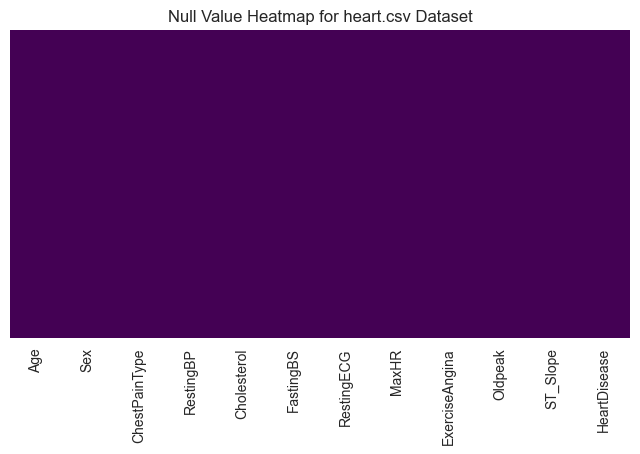

Missing Values Counts:
 Series([], dtype: int64)


In [ ]:
# Checking for null values first

plt.figure(figsize=(8, 4))
sns.heatmap(df.isnull(), cbar=False, cmap="viridis", yticklabels=False)
plt.title("Null Value Heatmap for heart.csv Dataset")
plt.show()

print("Missing Values Counts:\n", df.isnull().sum()[df.isnull().sum() > 0])

In [8]:
# Checking for duplicate values

duplicate_count = df.duplicated().sum()
print(f"Number of duplicate rows in the heart.csv dataset: {duplicate_count}")

Number of duplicate rows in the heart.csv dataset: 0


***OBSERVATION:***

- The dataset contains no missing values and no duplicate rows. However, further investigation is needed to ascertain that the dataset is ready for model training.

In [9]:
# Checking for unique values in categorical columns

categorical_cols = df.select_dtypes(include=["object", "category", "str"]).columns
for col in categorical_cols:
    unique_values = df[col].unique()
    print(f"Unique values in '{col}': {unique_values}")

Unique values in 'Sex': <ArrowStringArray>
['M', 'F']
Length: 2, dtype: str
Unique values in 'ChestPainType': <ArrowStringArray>
['ATA', 'NAP', 'ASY', 'TA']
Length: 4, dtype: str
Unique values in 'RestingECG': <ArrowStringArray>
['Normal', 'ST', 'LVH']
Length: 3, dtype: str
Unique values in 'ExerciseAngina': <ArrowStringArray>
['N', 'Y']
Length: 2, dtype: str
Unique values in 'ST_Slope': <ArrowStringArray>
['Up', 'Flat', 'Down']
Length: 3, dtype: str


***OBSERVATION:***

- The dataset contains five categorical columns that require encoding or transformation before model training.

--------------------------------

### ***PHASE 2: Univariate Analysis - Feature Distributions***
- Examine the distribution of each feature individually.
- Identify skewness, class imbalance, abnormal values, and clinically meaningful patterns.


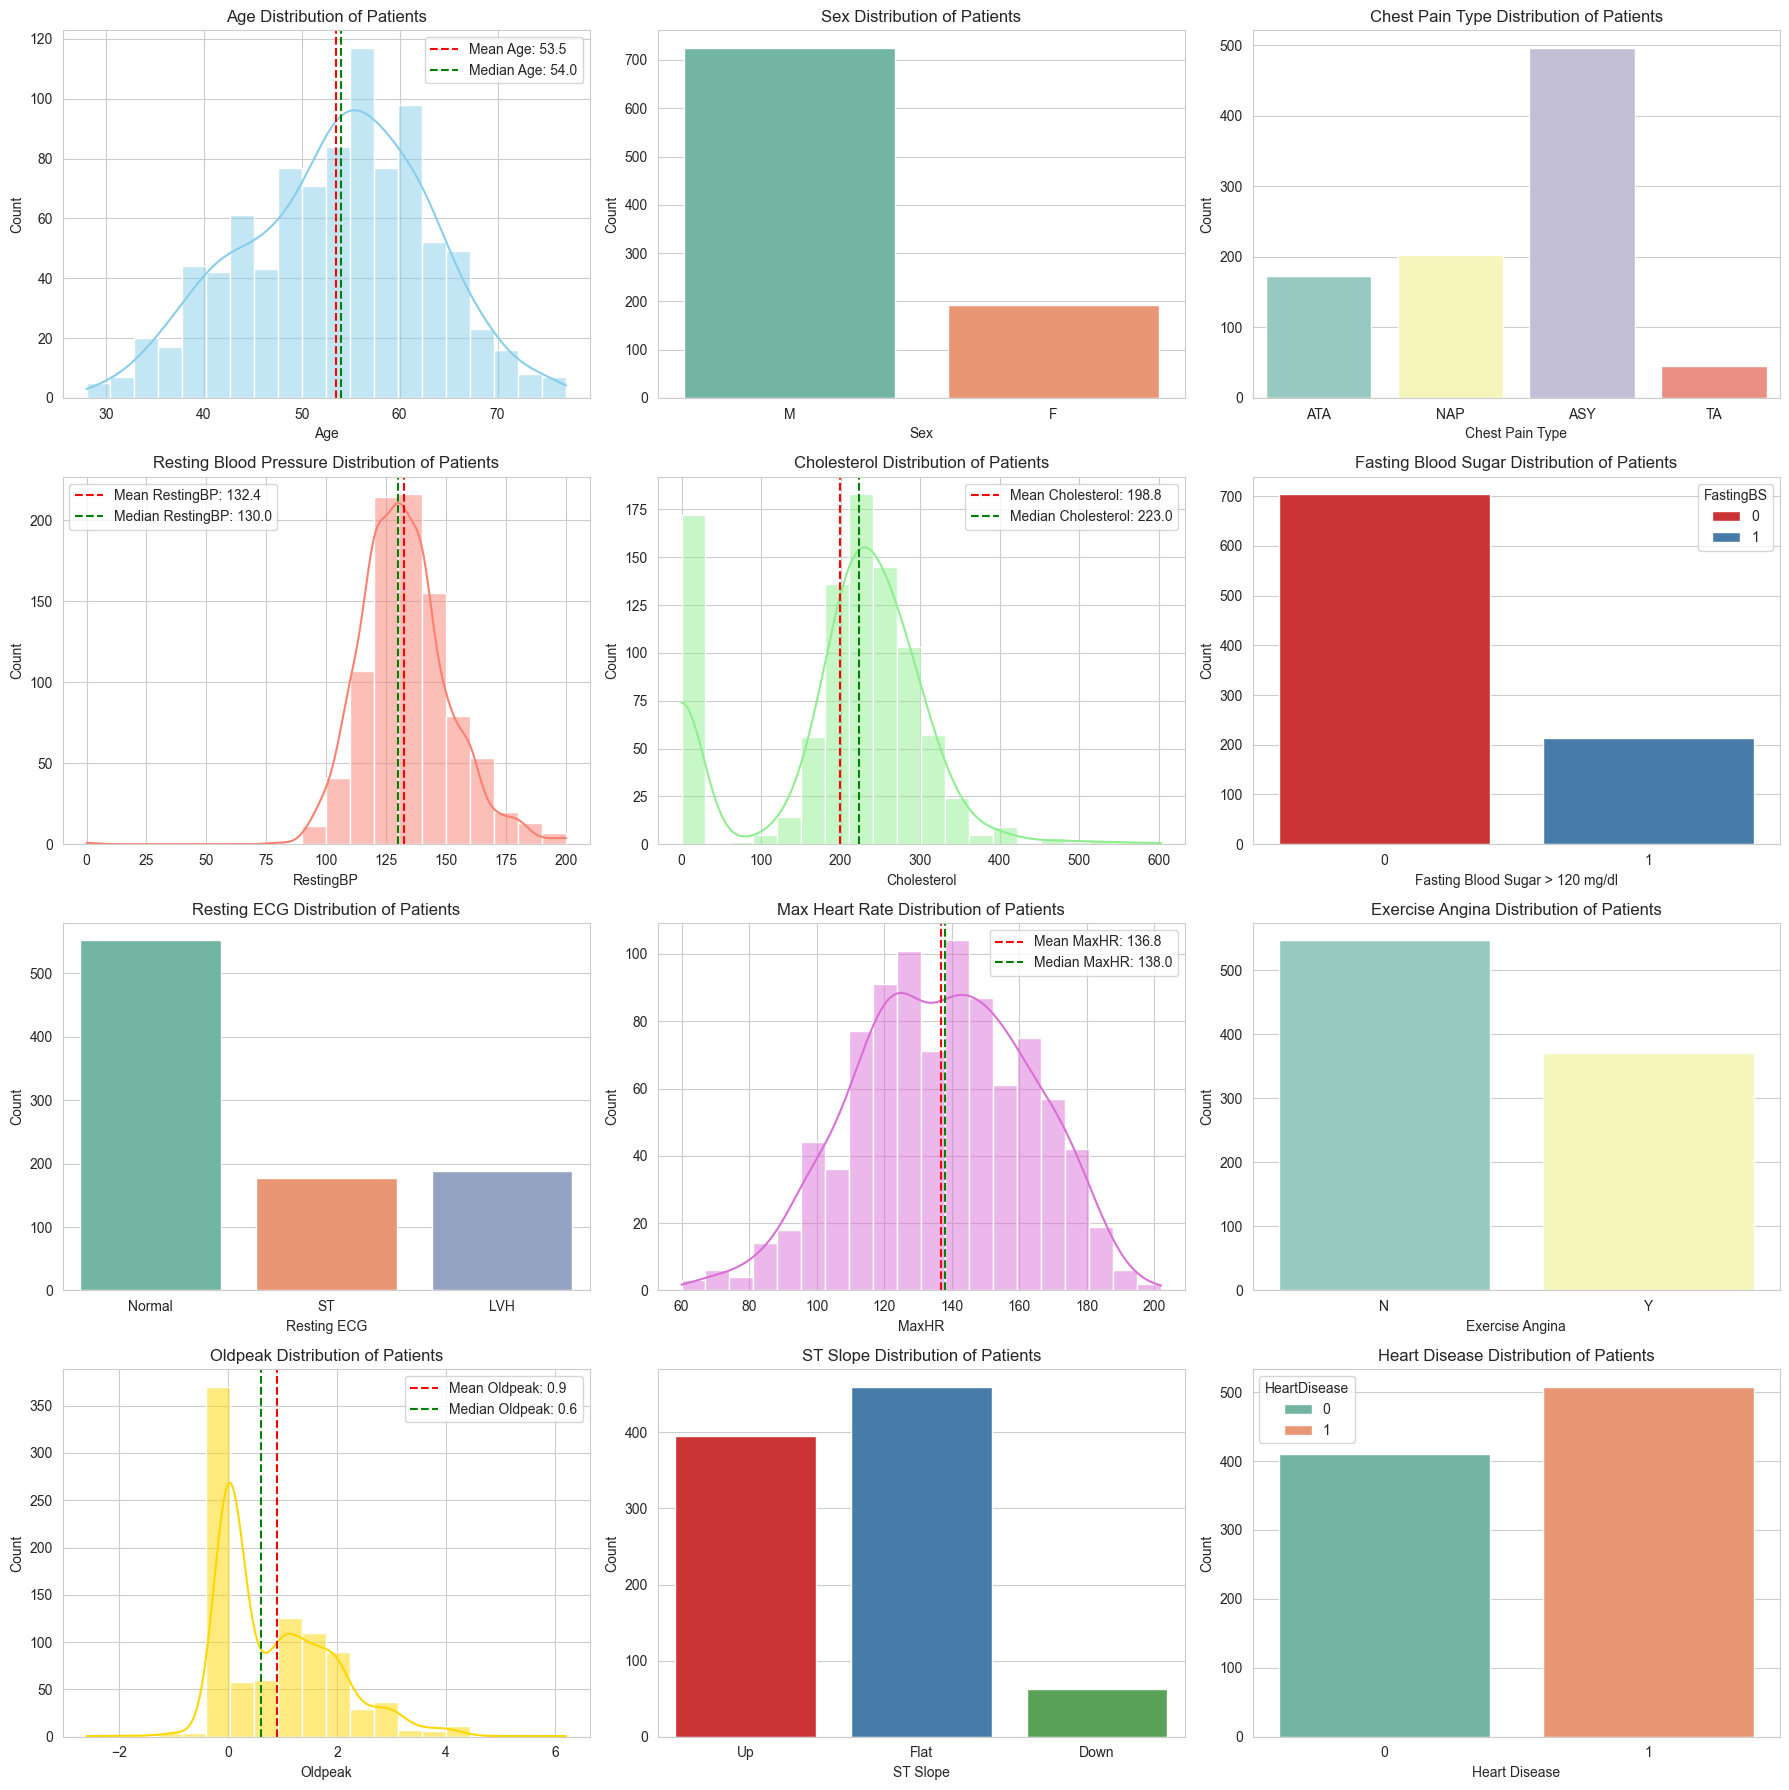

In [ ]:
# Histograms for numerical features and count plots for categorical features

plt.figure(figsize=(18, 18))

# Plot 1: Age distribution
plt.subplot(4, 3, 1)
sns.histplot(df["Age"], bins=20, kde=True, color="skyblue")
plt.title("Age Distribution of Patients")
plt.axvline(df["Age"].mean(), color="red", linestyle="--", label=f"Mean Age: {df['Age'].mean():.1f}")
plt.axvline(df["Age"].median(), color="green", linestyle="--", label=f"Median Age: {df['Age'].median():.1f}")
plt.legend()

# Plot 2: Sex distribution
plt.subplot(4, 3, 2)
sns.countplot(x="Sex", data=df, hue="Sex", palette="Set2")
plt.title("Sex Distribution of Patients")
plt.xlabel("Sex")
plt.ylabel("Count")

# Plot 3: Chest Pain Type distribution
plt.subplot(4, 3, 3)
sns.countplot(x="ChestPainType", data=df, hue="ChestPainType", palette="Set3")
plt.title("Chest Pain Type Distribution of Patients")
plt.xlabel("Chest Pain Type")
plt.ylabel("Count")

# Plot 4: Resting Blood Pressure distribution
plt.subplot(4, 3, 4)
sns.histplot(df["RestingBP"], bins=20, kde=True, color="salmon")
plt.title("Resting Blood Pressure Distribution of Patients")
plt.axvline(df["RestingBP"].mean(), color="red", linestyle="--", label=f"Mean RestingBP: {df['RestingBP'].mean():.1f}")
plt.axvline(df["RestingBP"].median(), color="green", linestyle="--", label=f"Median RestingBP: {df['RestingBP'].median():.1f}")
plt.legend()

# Plot 5: Cholesterol distribution
plt.subplot(4, 3, 5)
sns.histplot(df["Cholesterol"], bins=20, kde=True, color="lightgreen")
plt.title("Cholesterol Distribution of Patients")
plt.axvline(df["Cholesterol"].mean(), color="red", linestyle="--", label=f"Mean Cholesterol: {df['Cholesterol'].mean():.1f}")
plt.axvline(df["Cholesterol"].median(), color="green", linestyle="--", label=f"Median Cholesterol: {df['Cholesterol'].median():.1f}")
plt.legend()

# Plot 6: Fasting Blood Sugar distribution
plt.subplot(4, 3, 6)
sns.countplot(x="FastingBS", data=df, hue="FastingBS", palette="Set1")
plt.title("Fasting Blood Sugar Distribution of Patients") 
plt.xlabel("Fasting Blood Sugar > 120 mg/dl")
plt.ylabel("Count")

# Plot 7: Resting ECG distribution
plt.subplot(4, 3, 7)
sns.countplot(x="RestingECG", data=df, hue="RestingECG", palette="Set2")
plt.title("Resting ECG Distribution of Patients")
plt.xlabel("Resting ECG")
plt.ylabel("Count")

# Plot 8: Max Heart Rate distribution
plt.subplot(4, 3, 8)
sns.histplot(df["MaxHR"], bins=20, kde=True, color="orchid")
plt.title("Max Heart Rate Distribution of Patients")
plt.axvline(df["MaxHR"].mean(), color="red", linestyle="--", label=f"Mean MaxHR: {df['MaxHR'].mean():.1f}")
plt.axvline(df["MaxHR"].median(), color="green", linestyle="--", label=f"Median MaxHR: {df['MaxHR'].median():.1f}")
plt.legend()

# Plot 9: Exercise Angina distribution
plt.subplot(4, 3, 9)
sns.countplot(x="ExerciseAngina", data=df, hue="ExerciseAngina", palette="Set3")
plt.title("Exercise Angina Distribution of Patients")
plt.xlabel("Exercise Angina")
plt.ylabel("Count")

# Plot 10: Oldpeak distribution
plt.subplot(4, 3, 10)
sns.histplot(df["Oldpeak"], bins=20, kde=True, color="gold")
plt.title("Oldpeak Distribution of Patients")
plt.axvline(df["Oldpeak"].mean(), color="red", linestyle="--", label=f"Mean Oldpeak: {df['Oldpeak'].mean():.1f}")
plt.axvline(df["Oldpeak"].median(), color="green", linestyle="--", label=f"Median Oldpeak: {df['Oldpeak'].median():.1f}")
plt.legend()

# Plot 11: ST Slope distribution
plt.subplot(4, 3, 11)
sns.countplot(x="ST_Slope", data=df, hue="ST_Slope", palette="Set1")
plt.title("ST Slope Distribution of Patients")
plt.xlabel("ST Slope")
plt.ylabel("Count") 

# Plot 12: Heart Disease distribution
plt.subplot(4, 3, 12)
sns.countplot(x="HeartDisease", data=df, hue="HeartDisease", palette="Set2")
plt.title("Heart Disease Distribution of Patients")
plt.xlabel("Heart Disease")
plt.ylabel("Count")


plt.tight_layout()
plt.show()

***OBSERVATION:***

- __AGE:__ The age distribution isn't heavily skewed, since the mean and median are close (53.5 and 54.0, respectively). Most patients are between 40 to 60 years old, with a few outliers in the 20s and 70s.

- __SEX:__ More than 700 of the patients are male while there are not less than 200 female patients. This is a significant imbalance in the dataset, which may affect the performance of machine learning models trained on this data.

- __CHEST PAIN TYPE:__ Most patients experience the ASY chest pain type (~490+), followed by NAP (200), ATA (<200), and the least common being TA (<50).

- __RESTING BLOOD PRESSURE:__ The resting blood pressure (RestingBP) has a mean of __132.4mm Hg__, which is slightly higher than the median of 130mm Hg, which would indicate a slight __right skew__ in the distribution. According to NHLBI, NIH (2024), a normal resting blood pressure is less than 120/80mm Hg. However, both the mean and median are above the normal range, assuming that RestingBP represents Systolic Blood Pressure.  This suggests that a significant portion of the patients in the dataset have high blood pressure, which is a known risk factor for heart disease.

- __CHOLESTEROL:__ The mean cholesterol level is __198.8 mg/dl__, which is lower than the median of __223.0 mg/dl__. This indicates a negative (left) skew in the distribution. According to Cleveland Clinic (2025),  a normal total cholesterol level should be less than 200 mg/dl. While the mean is just below the normal threshold, the median or the middle value is above it. This would suggest that more than half of the patients in the dataset have borderline high cholesterol. This is a significant finding since even though borderline high cholesterol is easier to manage than high cholesterol, it still increases the risk of heart disease. __Furthermore, there are at least 170 patients with 0 cholesterol levels, which is likely an error in the dataset and should be investigated further__.

- __FASTING BLOOD SUGAR:__ The specified clinical threshold given in the dataset for fasting blood sugar is > 120 mg/dl, which indicates diabetic or prediabetic ranges. Since the column values are binary (0 or 1), this means that 1 represents patients with a fasting blood dugar over 120 mg/dl, while 0 means patients with normal fasting blood sugar levels. In the dataset, there are an estimated of 210 patients with high fasting blood sugar levels (1) or approximately 23%.

- __RESTING ELECTROCARDIOGRAPHIC RESULTS (RestingECG):__ The bar graph shows that the majority of patients have a normal result (~500+), followed by left ventricular hypertrophy (~190), and ST-T wave abnormalities (~180).

- __MAX HEART RATE:__ The mean maximum heart rate achieved is __136.8 bpm__, which is slightly lower than the median of __138.0 bpm__. This indicates a slightly left-skewed distribution. Since normal max heart rates differ by age, further analysis would be needed to truly determine if this is a concerning value. 

- __EXERCISE INDUCED ANGINA:__ The bar graph shows that most patients (500+) do not experience exercise-induced angina (0), while a smaller portion of patients (360+) do experience it (1).

- __OLDPEAK:__ It is the ST depression induced by exercise relative to rest. The mean oldpeak value is __0.9__, which is slightly higher than the median of __0.6__. This indicates a slight right skew in the distribution. A normal oldpeak level is typically 0 or close to 0. While there is a massive spike at 0 (350+ patients), there are also a significant number of patients with elevated oldpeak values, which could indicate a higher risk of heart disease as their hearts are struggling for oxygen during exercise.

- __ST SLOPE:__ The ST slope measures the angle or direction of the ST segment as the heart tries to recover from exercise (Venkatesan, 2009). The bar graph shows that most patients have a flat ST slope (0) (450+), followed by an upsloping ST slope (1) (~390), and the least common is a downsloping ST slope (2) (~70).

- __HEART DISEASE:__ The bar graph shows that there are more patients with heart disease (1) (500+) than patients without heart disease (0) (~410).


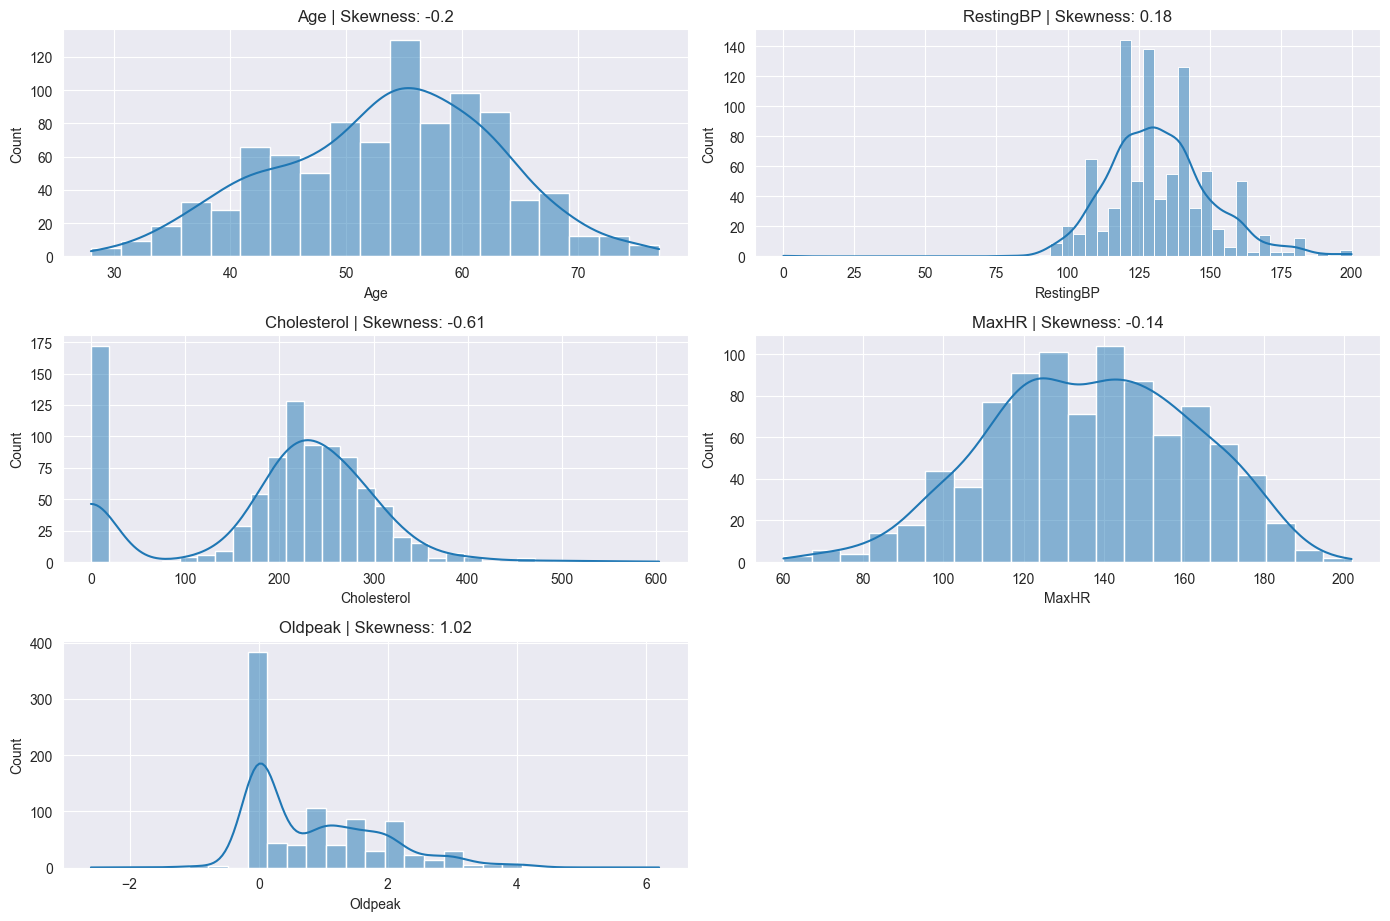

In [ ]:
# Kernel Density Estimate (KDE) plots for numerical features for better visualization of distributions

sns.set_style("darkgrid")

numerical_cols = df.select_dtypes(include=["int64", "float64"]).columns.drop(["FastingBS", "HeartDisease"])
plt.figure(figsize=(14, len(numerical_cols) * 3))
for idx, feature in enumerate(numerical_cols, 1):
    plt.subplot(len(numerical_cols), 2, idx)
    sns.histplot(df[feature], kde=True)
    plt.title(f"{feature} | Skewness: {round(df[feature].skew(), 2)}")

plt.tight_layout()
plt.show()

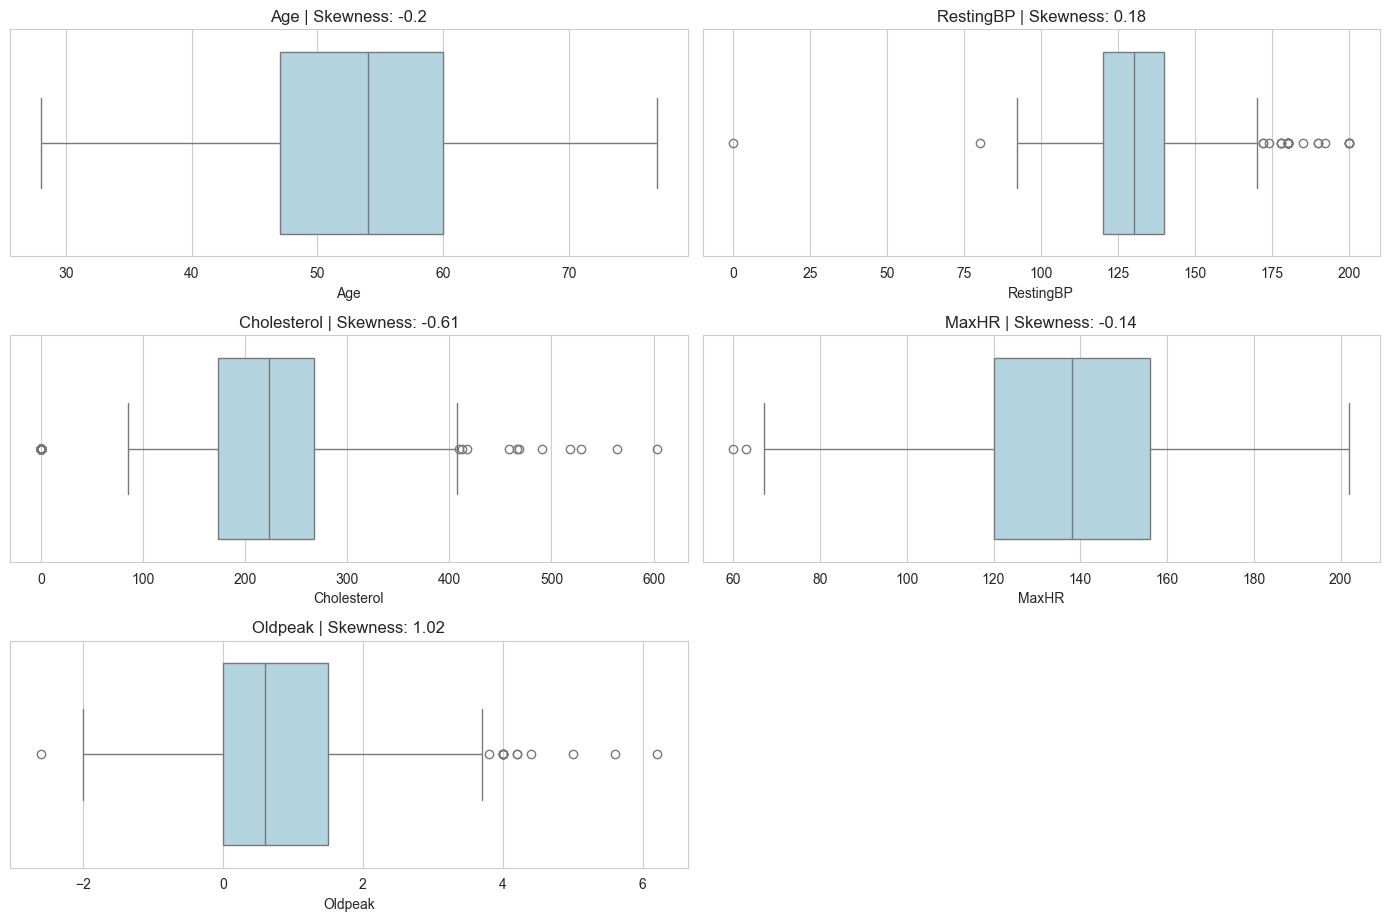

In [12]:
# Detecting outliers using box plots for numerical features

sns.set_style("whitegrid")
numerical_cols = df.select_dtypes(include=["int64", "float64"]).columns.drop(["FastingBS", "HeartDisease"])
plt.figure(figsize=(14, len(numerical_cols) * 3))
for idx, feature in enumerate(numerical_cols, 1):
    plt.subplot(len(numerical_cols), 2, idx)
    sns.boxplot(x=df[feature], color="lightblue")
    plt.title(f"{feature} | Skewness: {round(df[feature].skew(), 2)}")
plt.tight_layout()
plt.show()

***OBSERVATION:***

- The RestingBP column has a patient with 0 mm Hg, which is likely an error in the dataset. The same goes for the Cholesterol column, which has at least 170 patients with 0 mg/dl cholesterol levels. These values may need to be removed or imputed before training machine learning models on this dataset.
- This proves that the dataset is in need of further cleaning and preprocessing even though their are no missing values or duplicate rows detected before. 
- However, the outliers on the far right of the boxplots are considered medical outliers, hence, they should be preserved in the dataset as they represent real patients with high blood pressure and cholesterol levels, which are important for training machine learning models to predict heart disease risk.


--------------------------------

### ***PHASE 3: Handling Zero Outliers in RestingBP and Cholesterol***
- Treat impossible zero values in `RestingBP` and `Cholesterol` before continuing the analysis.
- Preserve clinically plausible outliers that may represent real high-risk patients.


In [13]:
print("================================================")

# Replace the impossible 0s with NaN first
df['RestingBP'] = df['RestingBP'].replace(0, np.nan)
df['Cholesterol'] = df['Cholesterol'].replace(0, np.nan)

# then fill them with the median of their respective columns
df['RestingBP'] = df['RestingBP'].fillna(df['RestingBP'].median())
df['Cholesterol'] = df['Cholesterol'].fillna(df['Cholesterol'].median())

# 3. Print the new minimums to verify the 0s are gone!
print("New Minimum RestingBP:", df['RestingBP'].min())
print("New Minimum Cholesterol:", df['Cholesterol'].min())

print("================================================")

New Minimum RestingBP: 80.0
New Minimum Cholesterol: 85.0


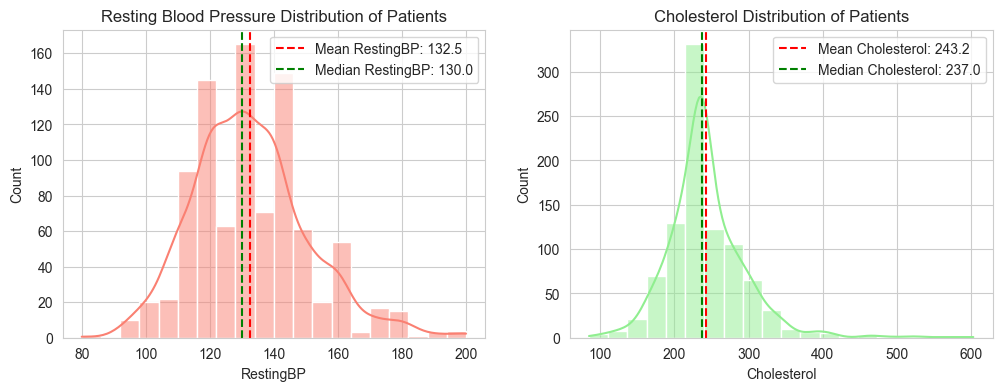

In [ ]:
# Checking Cholesterol and RestingBP distributions again after handling the 0 outliers

plt.figure(figsize=(12, 4))
# Resting Blood Pressure distribution
plt.subplot(1, 2, 1)
sns.histplot(df["RestingBP"], bins=20, kde=True, color="salmon")
plt.title("Resting Blood Pressure Distribution of Patients")
plt.axvline(df["RestingBP"].mean(), color="red", linestyle="--", label=f"Mean RestingBP: {df['RestingBP'].mean():.1f}")
plt.axvline(df["RestingBP"].median(), color="green", linestyle="--", label=f"Median RestingBP: {df['RestingBP'].median():.1f}")
plt.legend()

# Cholesterol distribution
plt.subplot(1, 2, 2)
sns.histplot(df["Cholesterol"], bins=20, kde=True, color="lightgreen")
plt.title("Cholesterol Distribution of Patients")
plt.axvline(df["Cholesterol"].mean(), color="red", linestyle="--", label=f"Mean Cholesterol: {df['Cholesterol'].mean():.1f}")
plt.axvline(df["Cholesterol"].median(), color="green", linestyle="--", label=f"Median Cholesterol: {df['Cholesterol'].median():.1f}")
plt.legend()

***OBSERVATION:***

- There are no zero values in both the columns anymore, which means that the impossible outliers have been successfully handled.


--------------------------------

### ***PHASE 4: Bivariate Analysis - Heart Disease Cases Across Features***
- Compare each feature against the `HeartDisease` target.
- Identify which clinical features show visible separation between patients with and without heart disease.


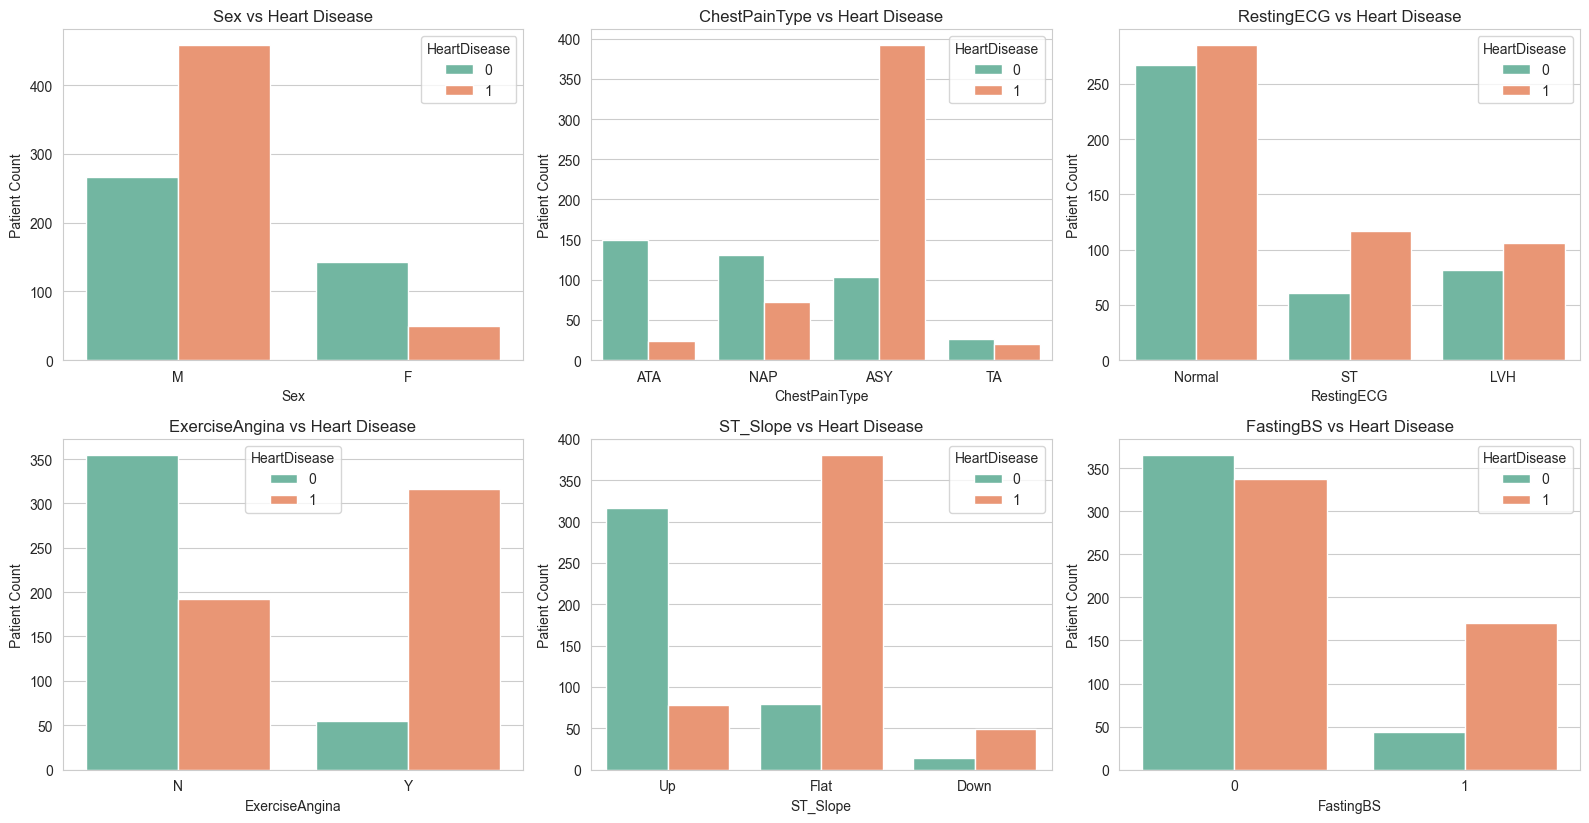

In [15]:
# Categorical features count plots with hue based on HeartDisease

sns.set_style("whitegrid")

# Grab categorical columns and add the binary FastingBS
cat_cols = df.select_dtypes(include=["object", "category", "str"]).columns.tolist()
if "FastingBS" not in cat_cols:
    cat_cols.append("FastingBS")

# Set up the 3x3 grid
plt.figure(figsize=(16, 12))

for idx, feature in enumerate(cat_cols, 1):
    plt.subplot(3, 3, idx)
    # hue="HeartDisease" splits the data by our target variable
    sns.countplot(data=df, x=feature, hue="HeartDisease", palette="Set2")
    plt.title(f"{feature} vs Heart Disease")
    plt.xlabel(feature)
    plt.ylabel("Patient Count")

plt.tight_layout()
plt.show()

***OBSERVATION:***

- Over 450 of male patients have heart disease while there are less female patients with heart disease. This makes it a massive risk indicator for heart disease. 
- Patients who experience ASY chest pain type have a higher percentage of heart disease cases compared to the other chest pain types. This also makes it a strong predictor of heart disease. 
- Most heart disease cases occur with patients who have normal restingECG results, however, it can be observed that patients with ST and LVH restingECG results have a higher proportionate risk (likelihood) of having a heart disease compared to those with normal restingECG results.
- Patients with exercise-induced angina have a higher percentage of heart disease cases compared to those without exercise-induced angina.
- Patients with a flat ST slope have a higher percentage of heart disease cases compared to those with upsloping and downsloping ST slopes.
- Patients with normal blood sugar can also have heart disease, but a vast majority of patients with high fasting blood sugar levels have heart disease. This makes it a strong predictor of heart disease.


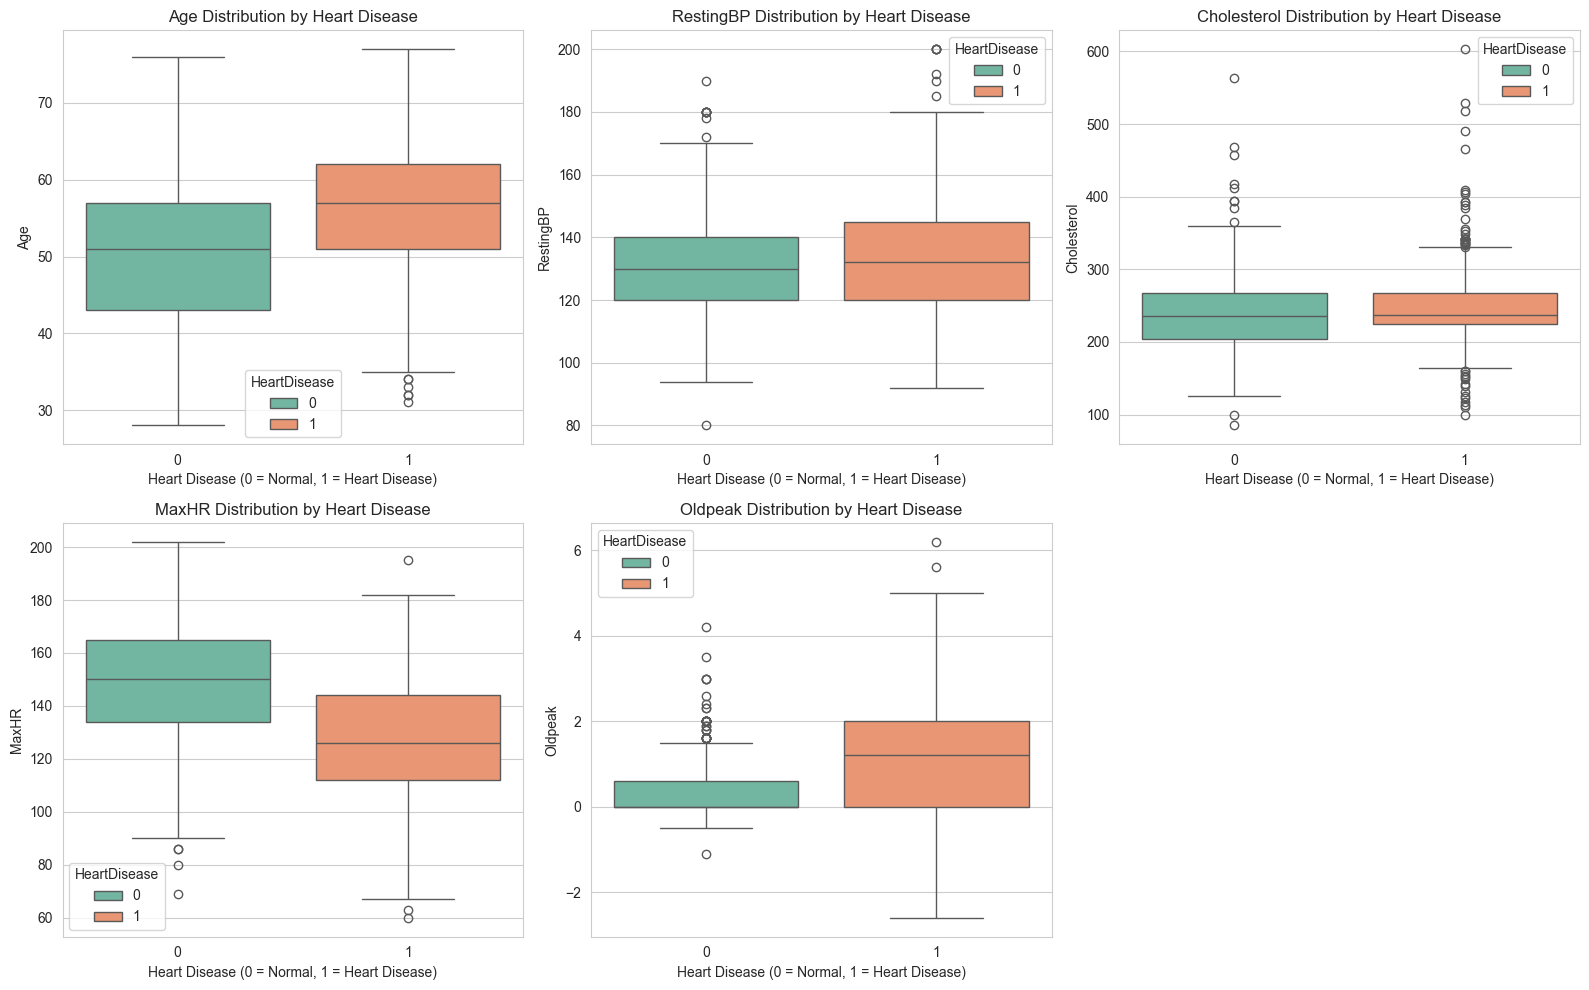

In [16]:
# Numerical features box plots with hue based on HeartDisease

num_cols = df.select_dtypes(include=["int64", "float64"]).columns.drop(["FastingBS", "HeartDisease"])

plt.figure(figsize=(16, 10))

for idx, feature in enumerate(num_cols, 1):
    plt.subplot(2, 3, idx)
    sns.boxplot(data=df, x="HeartDisease", y=feature, hue="HeartDisease", palette="Set2")
    plt.title(f"{feature} Distribution by Heart Disease")
    plt.xlabel("Heart Disease (0 = Normal, 1 = Heart Disease)")
    plt.ylabel(feature)

plt.tight_layout()
plt.show()

***OBSERVATION:***

- Patients with heart disease are mostly around 51 to 63 years old, with a few patients in their 30s having heart disease as well. 
- Most patients with normal resting blood pressure levels do not exceed 140 mm Hg, while there are some outliers that goes beyond 160 mm Hg. Resting blood pressure may not be a strong predictor of heart disease in this case since patients with normal and high resting blood pressure levels almost have a similar distribution.
- Most patients have bordeline high and high cholesterol levels. However, patients with heart disease tend to have a starting cholesterol level of around 220 mg/dl, but it is not really a strong predictor since there are many patients with low cholesterol levels who also have heart disease.
- Patients with heart disease tend to have a lower maximum heart rate compared to those without heart disease. 
- Patients with no heart disease are mostly clustered at 0 oldpeak value, while most patients with heart disease tend to have a higher oldpeak value (more than 1 and even reaching up to 6). This makes a strong predictor for heart disease. 


--------------------------------

### ***PHASE 5: Multivariate Analysis - Correlation and Pair Plot Review***
- Use correlation analysis and pair plots to examine multi-feature relationships.
- Identify which combinations of variables most strongly separate heart disease cases from non-cases.


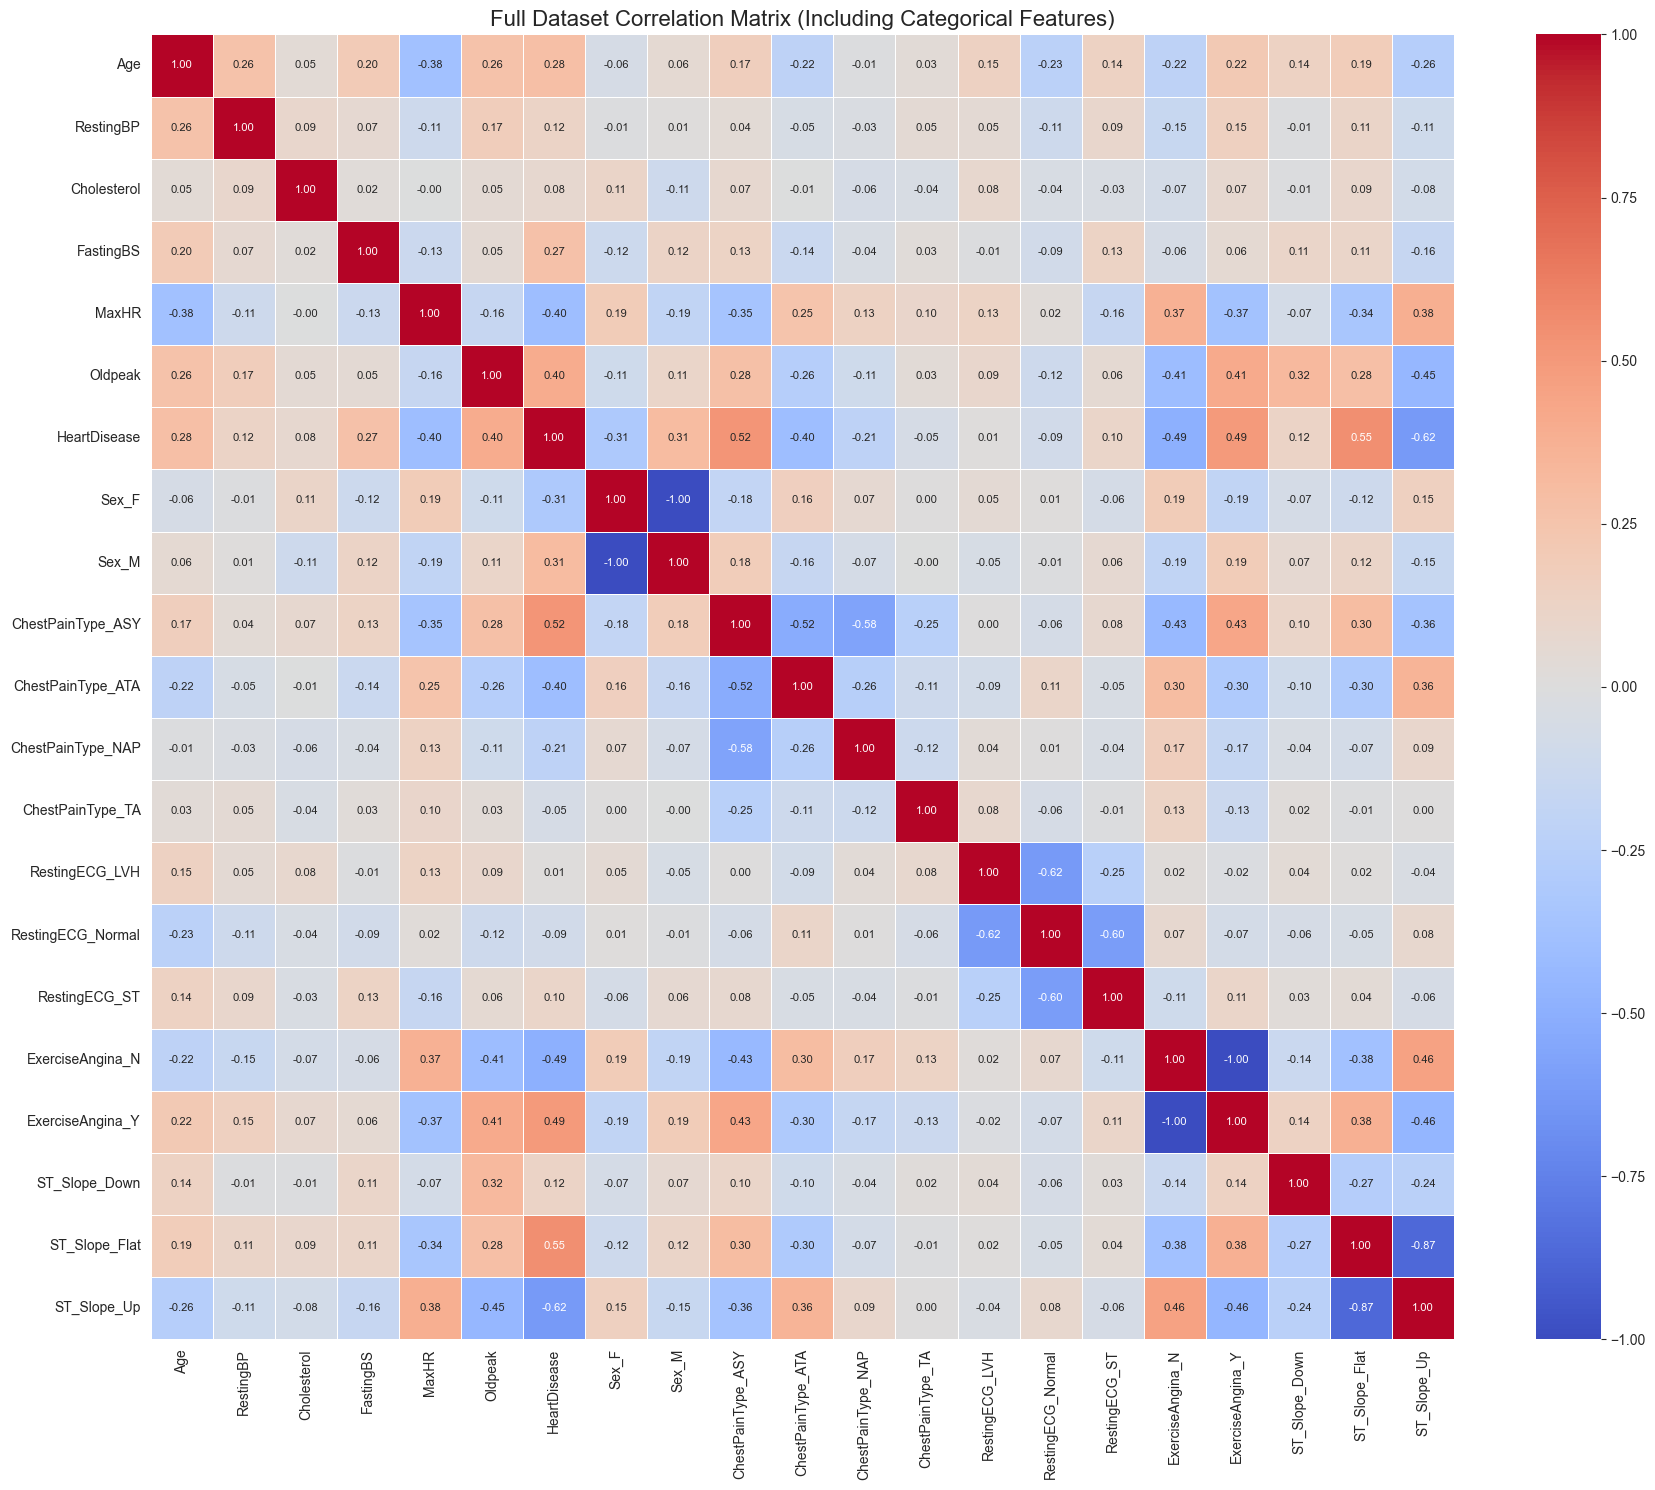

In [17]:
# Correlation matrix (heatmap)


# Convert categorical text columns into 1s and 0s
df_encoded = pd.get_dummies(df)

# Calculate the correlation matrix for all the features
corr_encoded = df_encoded.corr()
plt.figure(figsize=(18, 15))
sns.heatmap(corr_encoded, annot=True, cmap="coolwarm", fmt=".2f", 
            linewidths=0.5, vmin=-1, vmax=1, annot_kws={"size": 8})
plt.title("Full Dataset Correlation Matrix (Including Categorical Features)", fontsize=16)
plt.tight_layout()
plt.show()

***OBSERVATION:***

- Based on the correlation matrix for all the dataset's features, the features that show the __strongest positive correlation__ with heart disease are:

        - Flat: ST Slope (0.55)
        - ASY: chest pain type (0.52)
        - Yes: Exercise Induced Angina (0.49)

- Other features that show a positive correlation with heart disease but not as strong as the top 3 are:

        - Oldpeak (0.40)
        - Male: Sex (0.31)        
        - Age (0.28)
        - Fasting Blood Sugar (0.27)
        
- The features that show the __strongest negative correlation__ with heart disease are:

        - Upsloping: ST Slope (-0.62)
        - No: Exercise Induced Angina (-0.49)
        - Max Heart Rate (-0.40)
        - ATA: Chest Pain Type (-0.40)
        - Female: Sex (-0.31)
        - NAP: Chest Pain Type (-0.21)

- Based on this results, we can conclude that the feature with the __highest correlation with heart disease is the ST Slope__, specifically the __Upsloping (-0.62) and the Flat slope (0.55)__. This means that the behavior of the heart's recovery after exercise is the most important factor in determining heart disease risk in this dataset. __MaxHR and Oldpeak shows equal importance__ as well, with a correlation of -0.40 and 0.40, respectively. This means that __patients with heart disease tend to have a lower maximum heart rate and a higher oldpeak value compared to patients without heart disease.__

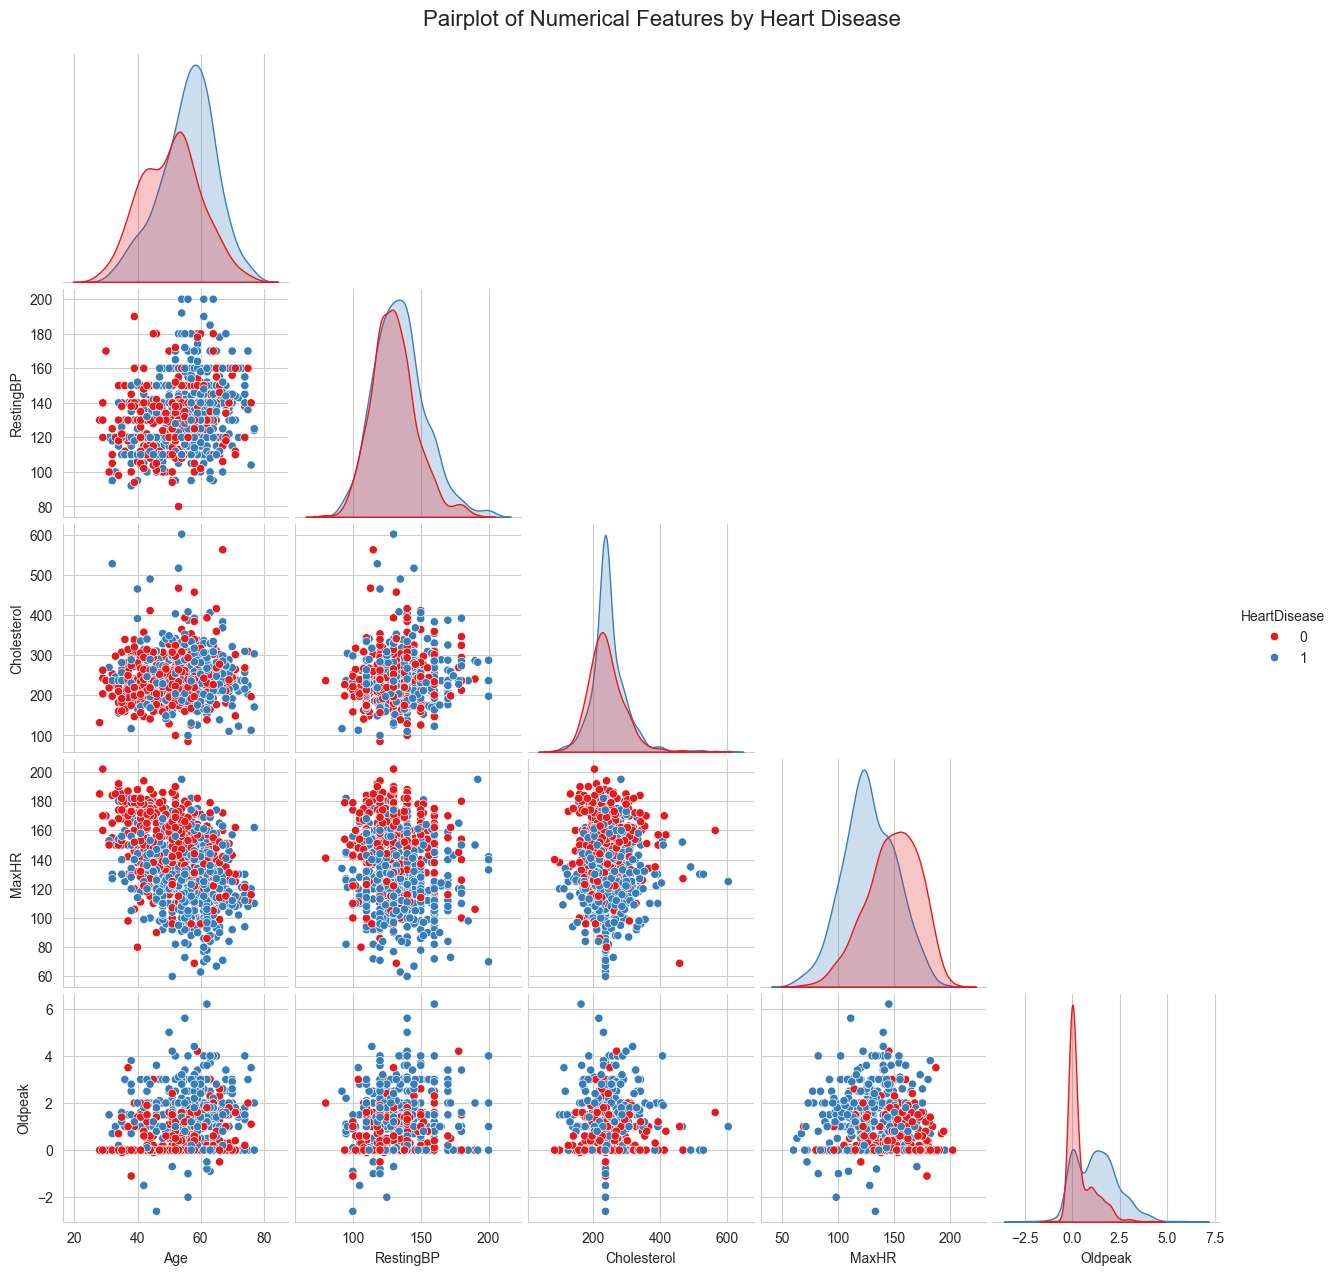

In [18]:
# Pair Plot for numerical features colored by HeartDisease

import seaborn as sns
import matplotlib.pyplot as plt

# Drop FastingBS from the pairplot since it's a binary feature
pairplot_cols = df.select_dtypes(include=["int64", "float64"]).columns.drop(["FastingBS"])
sns.pairplot(data=df[pairplot_cols], hue="HeartDisease", palette="Set1", corner=True, diag_kind="kde")
plt.suptitle("Pairplot of Numerical Features by Heart Disease", y=1.02, fontsize=16)
plt.show()

***OBSERVATION:***

- The pair plot further confirms the strong preDictors identified previously in the bivariate analysis and correlation matrix. Based on the pair plot of the dataset, 

        - RestingBP and Cholesterol do not show a clear separation between patients with and without heart disease, which suggests that they may not be strong predictors on their own.
        - Oldpeak and MaxHR show a clear separation between patients with and without heart disease. Patients with heart disease tend to have higher oldpeak values and lower MaxHR values. This confirms that oldpeak and MaxHR are indeed strong predictors of heart disease.

--------------------------------

### ***PHASE 6: Saving the Cleaned Dataset***
- Export the cleaned dataset for predictive and descriptive modeling.


In [ ]:
# --- FINAL EXPORT ---

print(f"Final shape: {df.shape}")
print(f"Missing values:\n{df.isnull().sum().sum()}")

# Save to CSV
df.to_csv("data/heart_cleaned.csv", index=False)

print("Data cleaning complete. File saved to 'data/heart_cleaned.csv'.")

Final shape: (918, 12)
Missing values:
0
Data cleaning complete. File saved to 'data/heart_cleaned.csv'.


--------------------------------
--------------------------------

# **3. PREDICTIVE MODELING**

### ***Decision Tree & Random Forest***

--------------------------------
--------------------------------


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report,
)
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

### ***PHASE 1: Data Preparation and Encoding***
- Load the cleaned heart disease dataset.
- Confirm the data integrity.
- Convert categorical clinical features into numerical form using one-hot encoding.
- Split the data into a stratified training/testing split.


In [2]:
# 1. Data Loading & Inspection
# Load the cleaned dataset from the exported CSV file and verify the first few rows.
heart_df = pd.read_csv("data/heart_cleaned.csv")

print("--- Dataset Preview ---")
print(heart_df.head(5), "\n")

print("--- Dataset Info ---")
heart_df.info()
print("\n")

--- Dataset Preview ---
   Age Sex ChestPainType  RestingBP  Cholesterol  FastingBS RestingECG  MaxHR  \
0   40   M           ATA      140.0        289.0          0     Normal    172   
1   49   F           NAP      160.0        180.0          0     Normal    156   
2   37   M           ATA      130.0        283.0          0         ST     98   
3   48   F           ASY      138.0        214.0          0     Normal    108   
4   54   M           NAP      150.0        195.0          0     Normal    122   

  ExerciseAngina  Oldpeak ST_Slope  HeartDisease  
0              N      0.0       Up             0  
1              N      1.0     Flat             1  
2              N      0.0       Up             0  
3              Y      1.5     Flat             1  
4              N      0.0       Up             0   

--- Dataset Info ---
<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          

In [3]:
# 2. One-Hot Encoding (Categorical to Numeric)
# Identify categorical columns dynamically and encode them into machine-readable binary features.
cat_columns = heart_df.select_dtypes(include=["object", "category", "string"]).columns.tolist()
print(f"Categorical columns detected for encoding: {cat_columns}\n")

# One-hot encode categorical features while dropping the first dummy variable for each category.
# This avoids the dummy variable trap and reduces perfect multicollinearity.
heart_encoded = pd.get_dummies(heart_df, columns=cat_columns, drop_first=True, dtype=int)

print("--- Encoded Feature Preview ---")
print(heart_encoded.head(10), "\n")

Categorical columns detected for encoding: ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']

--- Encoded Feature Preview ---
   Age  RestingBP  Cholesterol  FastingBS  MaxHR  Oldpeak  HeartDisease  \
0   40      140.0        289.0          0    172      0.0             0   
1   49      160.0        180.0          0    156      1.0             1   
2   37      130.0        283.0          0     98      0.0             0   
3   48      138.0        214.0          0    108      1.5             1   
4   54      150.0        195.0          0    122      0.0             0   
5   39      120.0        339.0          0    170      0.0             0   
6   45      130.0        237.0          0    170      0.0             0   
7   54      110.0        208.0          0    142      0.0             0   
8   37      140.0        207.0          0    130      1.5             1   
9   48      120.0        284.0          0    120      0.0             0   

   Sex_M  ChestPainType_ATA  

In [4]:
# 3. Feature-Target Separation
# Isolate the clinical features from the binary outcome label.
y = heart_encoded["HeartDisease"].copy()
X = heart_encoded.drop(columns=["HeartDisease"]).copy()

print("--- Feature / Target Separation ---")
print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}\n")

--- Feature / Target Separation ---
X shape: (918, 15)
y shape: (918,)



In [5]:
# 4. Train-Test Split (The Evaluation Framework)
# Split the dataset into an 80/20 train/test split with stratification to preserve
# the heart disease class balance across both sets.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

# Confirm the split sizes and verify the training/testing pipeline executed correctly.
print("--- Train/Test Split Shapes ---")
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape:  {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape:  {y_test.shape}")

--- Train/Test Split Shapes ---
X_train shape: (734, 15)
X_test shape:  (184, 15)
y_train shape: (734,)
y_test shape:  (184,)


--------------------------------


### ***PHASE 2: Model 1 - Decision Tree Classifier***
- Build a shallow decision tree to establish a transparent clinical baseline model.


In [6]:
# Initialize decision tree with controlled depth to avoid overfitting clinical data.
dt_model = DecisionTreeClassifier(max_depth=5, random_state=42)

dt_model.fit(X_train, y_train)

# Generate deterministic class predictions for test patients.
y_pred_dt = dt_model.predict(X_test)

# Generate probability estimates for the positive heart disease class.
y_proba_dt = dt_model.predict_proba(X_test)[:, 1]

print("Decision Tree finished training and prediction.")

Decision Tree finished training and prediction.


--------------------------------


### ***PHASE 3: Model 2 - Random Forest Classifier***
- Build a balanced ensemble model to improve robustness while controlling tree complexity.


In [7]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=7,
    class_weight="balanced",
    random_state=42,
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)
y_proba_rf = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest finished training and prediction.")

Random Forest finished training and prediction.


--------------------------------


### ***PHASE 4: Model Evaluation & Comparison***
- Compare Decision Tree and Random Forest performance on the held-out clinical test set.


In [8]:
# 1. Calculate standard classification metrics for both models.
dt_accuracy = accuracy_score(y_test, y_pred_dt)
dt_precision = precision_score(y_test, y_pred_dt)
dt_recall = recall_score(y_test, y_pred_dt)

rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf)
rf_recall = recall_score(y_test, y_pred_rf)

metrics_df = pd.DataFrame(
    {
        "Decision Tree": [dt_accuracy, dt_precision, dt_recall],
        "Random Forest": [rf_accuracy, rf_precision, rf_recall],
    },
    index=["Accuracy", "Precision", "Recall"],
).reset_index().rename(columns={"index": "Metric"})

print("--- Model Comparison Metrics ---")
print(metrics_df.to_string(index=False))
print("\n")

# In a clinical heart disease screening task, minimizing False Negatives is the top priority.
# A low Recall means sick patients may be missed and sent home, which is far more dangerous than a False Positive.
print(
    f"Recall comparison: Decision Tree Recall = {dt_recall:.3f}, Random Forest Recall = {rf_recall:.3f}."
)

--- Model Comparison Metrics ---
   Metric  Decision Tree  Random Forest
 Accuracy       0.728261       0.858696
Precision       0.754902       0.887755
   Recall       0.754902       0.852941


Recall comparison: Decision Tree Recall = 0.755, Random Forest Recall = 0.853.


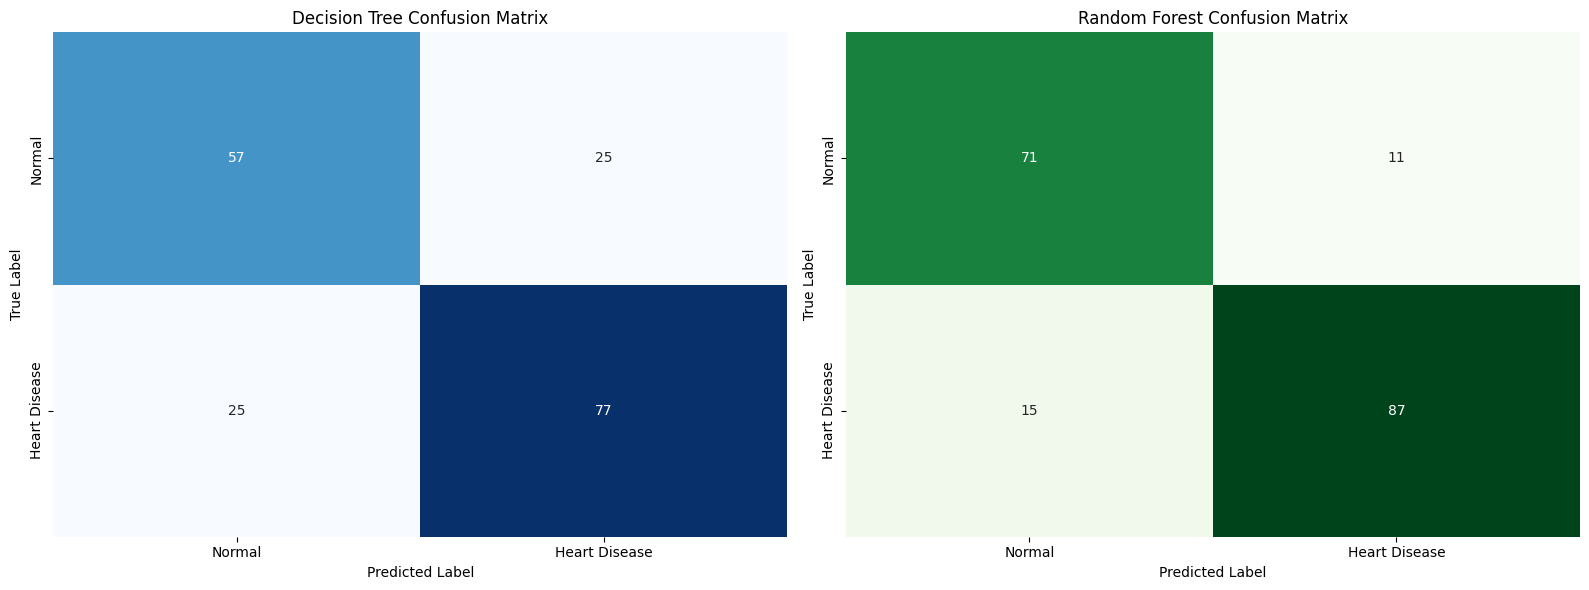

In [9]:
# 2. Side-by-side confusion matrices for clinical error analysis.
cm_dt = confusion_matrix(y_test, y_pred_dt)
cm_rf = confusion_matrix(y_test, y_pred_rf)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt="g",
    cmap="Blues",
    cbar=False,
    ax=axes[0],
    xticklabels=["Normal", "Heart Disease"],
    yticklabels=["Normal", "Heart Disease"],
)
axes[0].set_title("Decision Tree Confusion Matrix")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="g",
    cmap="Greens",
    cbar=False,
    ax=axes[1],
    xticklabels=["Normal", "Heart Disease"],
    yticklabels=["Normal", "Heart Disease"],
)
axes[1].set_title("Random Forest Confusion Matrix")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("True Label")

plt.tight_layout()
plt.show()

In [10]:
# 3. Print detailed classification reports to review class-specific precision, recall, and F1 scores.
print("--- Decision Tree Classification Report ---")
print(classification_report(y_test, y_pred_dt, target_names=["Normal", "Heart Disease"]))
print("--- Random Forest Classification Report ---")
print(classification_report(y_test, y_pred_rf, target_names=["Normal", "Heart Disease"]))

--- Decision Tree Classification Report ---
               precision    recall  f1-score   support

       Normal       0.70      0.70      0.70        82
Heart Disease       0.75      0.75      0.75       102

     accuracy                           0.73       184
    macro avg       0.73      0.73      0.73       184
 weighted avg       0.73      0.73      0.73       184

--- Random Forest Classification Report ---
               precision    recall  f1-score   support

       Normal       0.83      0.87      0.85        82
Heart Disease       0.89      0.85      0.87       102

     accuracy                           0.86       184
    macro avg       0.86      0.86      0.86       184
 weighted avg       0.86      0.86      0.86       184



***OBSERVATION:***

- When comparing two algorithms, the Random Forest model significantly outperformed the Decision Tree across every single metric. The overall accuracy of the Random Forest was 85.9%, compared to 72.8% for the Decision Tree. While a single Decision Tree is highly interpretable, it often struggles to generalize clinical nuances. Through utilizing an ensemble of 100 distinct decision trees, the Random Forest effectively smoothed out the noise and handled the complex, non-linear relationships within our patient data, which results in a highly robust predictive engine.

- The Precision metric tells us how reliable the model is when it actually raises an alarm. The Random Forest achieved a Precision of 88.8% for heart disease cases, commpared to the Decision Tree's 75.5%. Based on the Confusion Matrix data, the Decision Tree incorrectly flagged 25 healthy patients as having heart disease (false positives). The Random Forest slashed this number down to just 11. In a real-world hospital setting, this optimization is crucial. It means fewer healthy patients are subjects to unnecessary stress, expesntive secondary testing (like angiograms or stress tests), and misallocated hospital bed space.

- While Accuracy and Precision are excellent for operational efficiency, in cardiology, Recall is the absolute most critical metric. It answers the question, *"Out of all the patients who genuinely have heart disease, how many did we successfully find?"* The Random Forest improved our Recall from 75.5% to 85.3%. Based on the Confusion Matrix, out of the 102 actual heart disease patients in our test set, the Decision Tree successfully identified 77 but entirely missed 25. The Random Forest successfully identified 87 sick patients, reducing the missed cases down to 15.

- To explain this to the board of healthcare administrators, we must weight the cost of our model's errors. A False Positive occurs when the algorithm tells a healthy patient they might have heart disease. The "danger" here is benign, which includes patient anxiety, a follow-up consultation, and wasted operational costs. However, a False Negative occurs when the algorithm tells a patient with severe cardiovascular risk that they are perfectly normal. The danger here is catastrophic. The patient is discharged without intervention, which potentially leads to a fatal myocardial infection (heart attack) at home. Therefore, by reducing False Negative from 25 down to 15, the Random Forest's Recall directly translates too lives saved, which is the goal of any clinical predictive model.


--------------------------------


### ***PHASE 5: Model Interpretability & Feature Importance***
- Translate the trained models into clinically actionable insights by visualizing the decision tree, extracting its rules, and comparing feature importances.


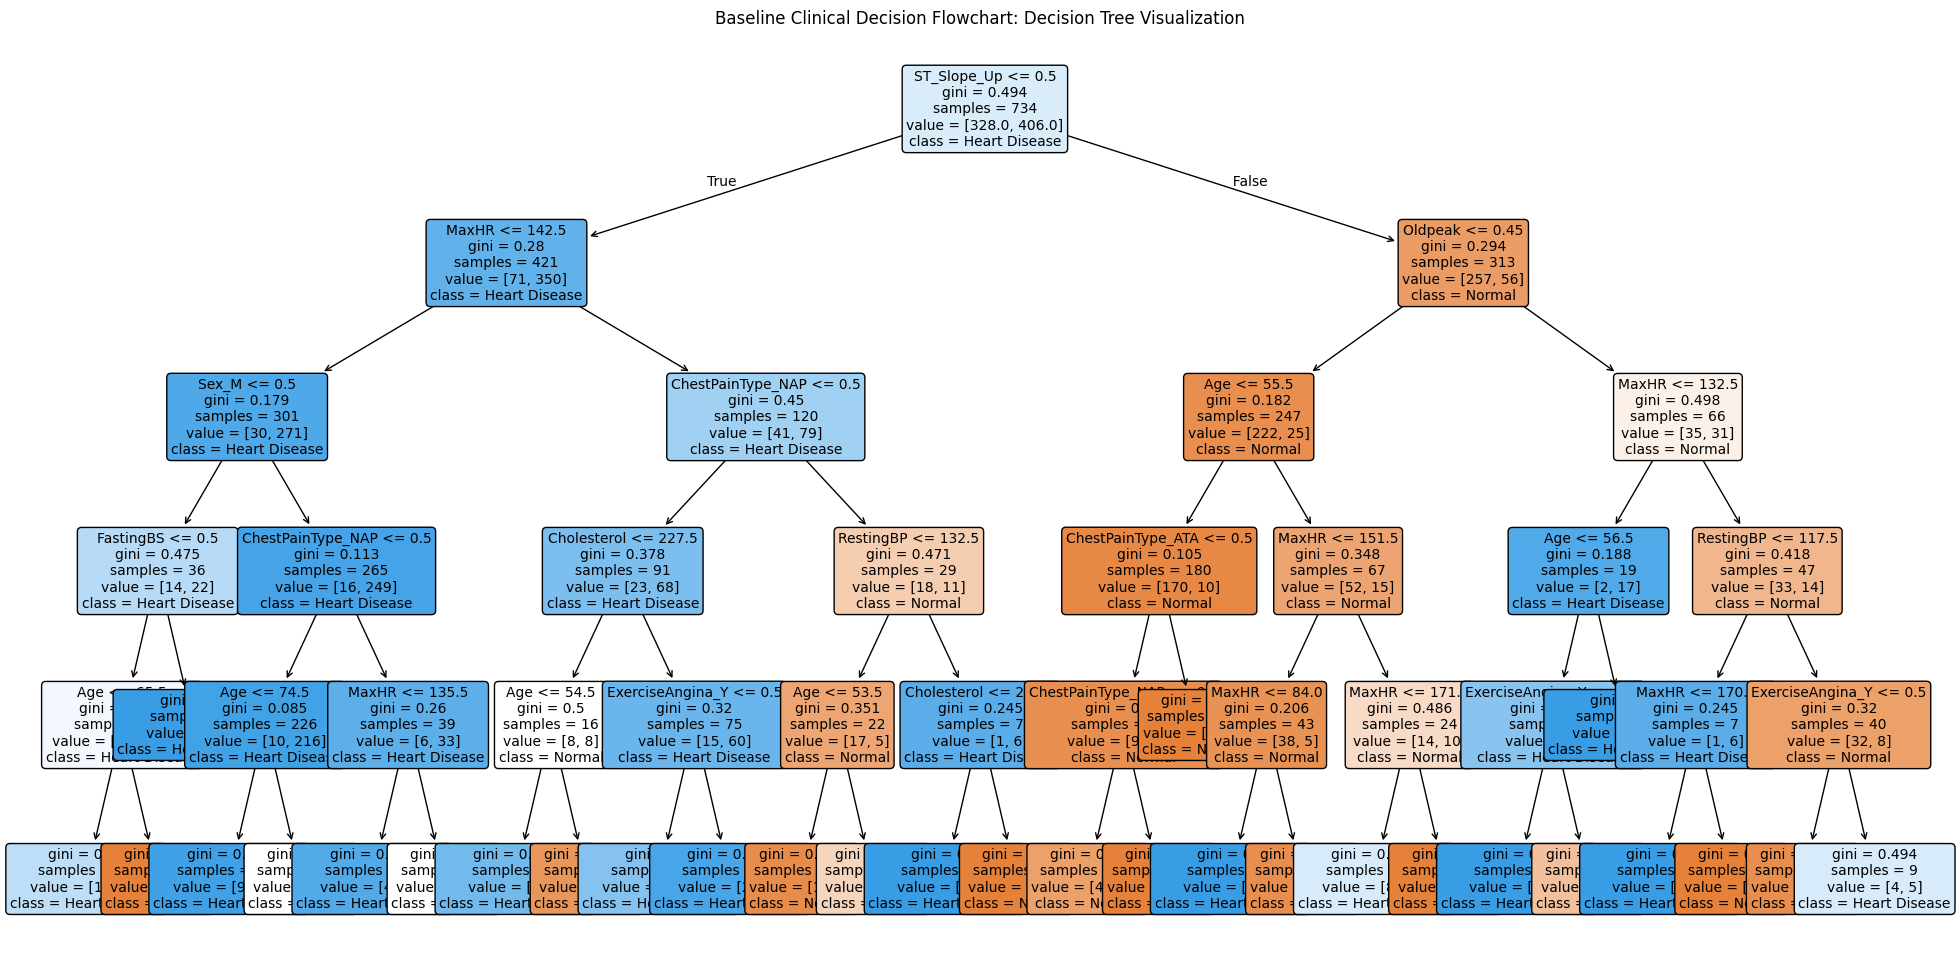

In [11]:
# 1. Decision Tree Visualization (The Clinical Flowchart)
plt.figure(figsize=(24, 12))
plot_tree(
    dt_model,
    feature_names=X.columns,
    class_names=["Normal", "Heart Disease"],
    filled=True,
    rounded=True,
    fontsize=10,
)
plt.title("Baseline Clinical Decision Flowchart: Decision Tree Visualization")
plt.show()

In [12]:
# 2. Extracting Highly Readable Clinical Rules
print("--- Decision Tree Rules: Transparent Clinical If-Then Logic ---")
print(
    "The following rules represent the explicit decision logic used by the tree. "
    "These can be communicated to clinicians as transparent, data-driven guidance."
)
rule_text = export_text(dt_model, feature_names=list(X.columns))
print(rule_text)

--- Decision Tree Rules: Transparent Clinical If-Then Logic ---
The following rules represent the explicit decision logic used by the tree. These can be communicated to clinicians as transparent, data-driven guidance.
|--- ST_Slope_Up <= 0.50
|   |--- MaxHR <= 142.50
|   |   |--- Sex_M <= 0.50
|   |   |   |--- FastingBS <= 0.50
|   |   |   |   |--- Age <= 65.50
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- Age >  65.50
|   |   |   |   |   |--- class: 0
|   |   |   |--- FastingBS >  0.50
|   |   |   |   |--- class: 1
|   |   |--- Sex_M >  0.50
|   |   |   |--- ChestPainType_NAP <= 0.50
|   |   |   |   |--- Age <= 74.50
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- Age >  74.50
|   |   |   |   |   |--- class: 0
|   |   |   |--- ChestPainType_NAP >  0.50
|   |   |   |   |--- MaxHR <= 135.50
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- MaxHR >  135.50
|   |   |   |   |   |--- class: 0
|   |--- MaxHR >  142.50
|   |   |--- ChestPainType_NAP <= 0.50
|   |   |   |-

***OBSERVATION:***

- The Decision Tree visualization and the extracted If-Then rules provide a clear look "under the hood" of the baseline model. Based on this extracted text rules, the very first split (the root node) is based on ST_Slope_Up. If a patient does not have an upward ST slope, the model immediately investigates their MaxHR and Sex. This level of deterministic logic is highly valuable in a hospital setting because it allows a doctor to manually verify exactly why the algorithm flagged a patient as high risk. However, the Decision Tree's simplicity also means it may miss more complex interactions between features.


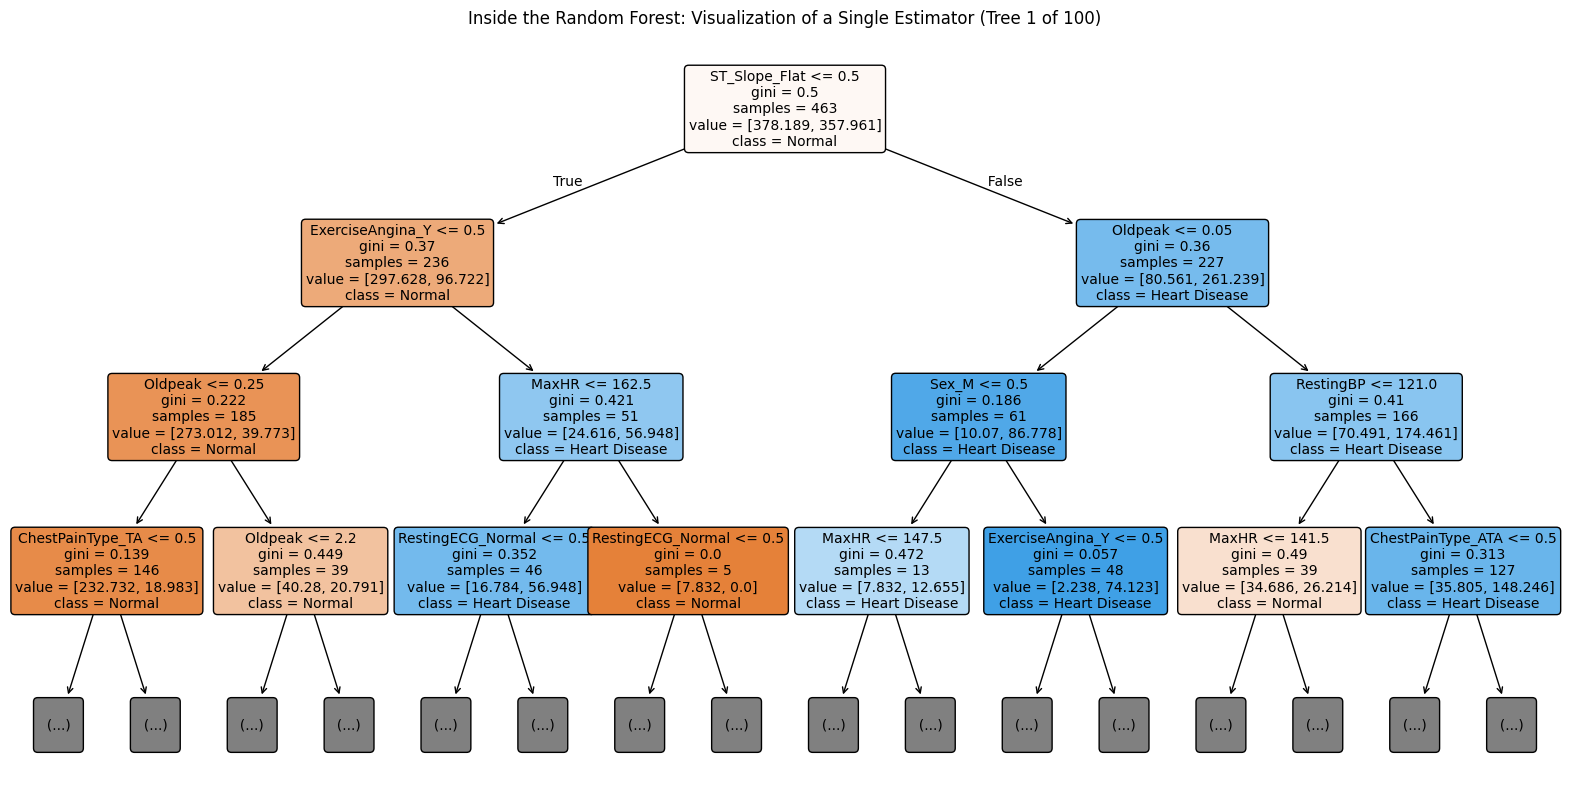

In [13]:
# 3. Random Forest Tree Visualization (Ensemble Illustration)
# Show one estimator from the forest to illustrate how the ensemble builds diverse trees.
single_rf_tree = rf_model.estimators_[0]

plt.figure(figsize=(20, 10))
plot_tree(
    single_rf_tree,
    feature_names=X.columns,
    class_names=["Normal", "Heart Disease"],
    filled=True,
    rounded=True,
    fontsize=10,
    max_depth=3,
)
plt.title("Inside the Random Forest: Visualization of a Single Estimator (Tree 1 of 100)")
plt.show()

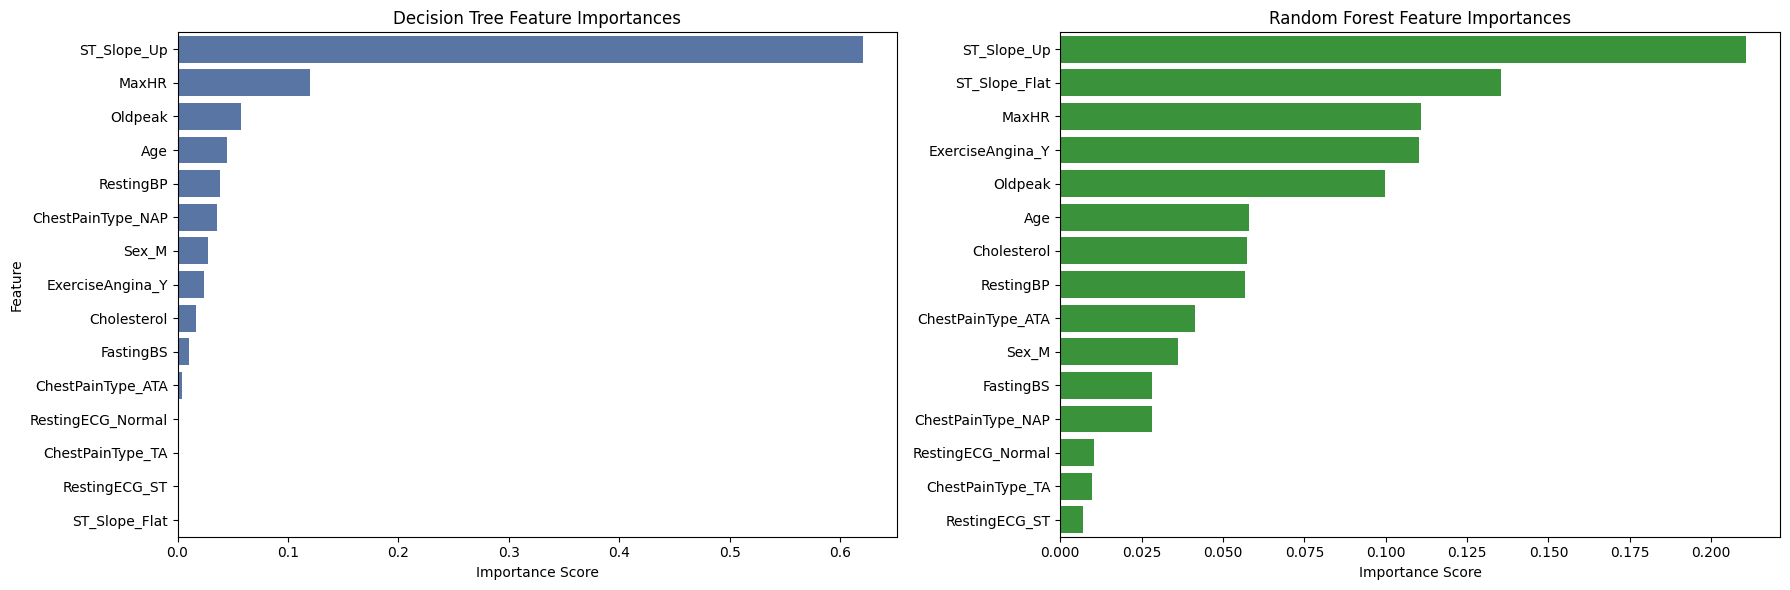

In [14]:
# 4. Feature Importance Comparison (Validating Risk Archetypes)
# Extract the learned importance scores from both models.
dt_importances = dt_model.feature_importances_
rf_importances = rf_model.feature_importances_

importance_df = pd.DataFrame(
    {
        "feature": X.columns,
        "Decision Tree Importance": dt_importances,
        "Random Forest Importance": rf_importances,
    }
)

# Sort importances in descending order for both models.
dt_sorted = importance_df.sort_values(by="Decision Tree Importance", ascending=False)
rf_sorted = importance_df.sort_values(by="Random Forest Importance", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

sns.barplot(
    x="Decision Tree Importance",
    y="feature",
    data=dt_sorted,
    ax=axes[0],
    color="#4c72b0",
)
axes[0].set_title("Decision Tree Feature Importances")
axes[0].set_xlabel("Importance Score")
axes[0].set_ylabel("Feature")

sns.barplot(
    x="Random Forest Importance",
    y="feature",
    data=rf_sorted,
    ax=axes[1],
    color="#2ca02c",
)
axes[1].set_title("Random Forest Feature Importances")
axes[1].set_xlabel("Importance Score")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

***OBSERVATION:***

- The Decision Tree is extremely top-heavy and hyper-fixated on a single metric. It assigns a massive >50% importance to ST_Slope_Up, meaning if a patient doesn't have an upward ST slope, the tree heavily relies on this one factor to drive the prediction. The subsequent features like Oldpeak, MaxHR, RestingBP, and FastingBS have significantly lower importance scores, barely registering above 10%. If effectively ifnores ExerciseAngina_Y and Cholesterol, which are clinically relevant.

- The Random Forest validates a much more holistic clinical archetype. While it still agrees that ST_Slope_Up is the most important predictor, it caps its influence at roughly 20%. The ensemble distributes the decision-making weight across a broad spectrum of clinical metrics. Oldpeak, MaxHR, Cholesterol, and Age all play vital, balanced roles. Notably, variables like ExerciseAngina_Y and Cholesterol, which the Decision Tree practically ignored, are recognized by the Random Forest as significant risk drivers. This balanced feature importance profile is more aligned with real-world clinical decision-making, where multiple factors interact to influence patient outcomes.


***TRADE-OFF: INTERPRETABILITY VS. PREDICTIVE POWER***

- This phase highlights the classic dilemma in clinical machine learning: the trade-off between the "glass box" and the "black box." Doctors naturally favor the Decision Tree because its interpretability is flawless. They can print the flowcahrt, hang it on the wall, and follow it with their own eyes. However, this simplicity comes at the cost of predictive power, as evidenced by its lower performance metrics. The Decision Tree has a much lower Recall, meaning it misses a significant number of true heart disease cases, which is unacceptable in a clinical setting.

- The Random Forest sacrifices that step-by-step transparency in exchange for massive predictive power. We cannot easily trace the exact path of a patient through 100 simultaneous trees. However, we can bridge this gap by providing the Feature Importance chart. By showing the medical boar what features the Random Forest uses to make its highly accurate predictions (proving it relies o logical, medically sound metrics like ST Slope and Oldpeak), we build the necessary trust to deploy the safer, more robust model into the real world. In medicine, when prioritizing patient safety and minimizing False Negatives, the predictive power of the ensemble must take precedence, even if it means sacrificing some interpretability.

--------------------------------


### ***PHASE 6: Clinical Risk Scoring (ACC/AHA Framework)***
- Translate the Random Forest probability outputs into evidence-based clinical risk tiers aligned with the ACC/AHA cardiovascular risk assessment framework.
- Based from the [2013 ACC/AHA Guideline on the Assessment of Cardiovascular Risk: A Report of the American College of Cardiology/American Heart Association Task Force on Practice Guidelines](https://www.ahajournals.org/doi/10.1161/01.cir.0000437741.48606.98)
    - Low Risk: <5%
    - Borderline Risk: 5% to <7.5%
    - Intermediate Risk: 7.5% to <20%
    - High Risk: ≥20%


In [15]:
# 1. Construct the Patient Risk DataFrame
patient_risk_df = X_test.reset_index(drop=True).copy()
patient_risk_df["True_Status"] = y_test.reset_index(drop=True)
patient_risk_df["Predicted_Status"] = y_pred_rf
patient_risk_df["Heart_Disease_Probability"] = y_proba_rf

print("--- Patient Risk DataFrame Created ---")
print(patient_risk_df.head(3))
print("\n")

--- Patient Risk DataFrame Created ---
   Age  RestingBP  Cholesterol  FastingBS  MaxHR  Oldpeak  Sex_M  \
0   46      115.0        237.0          0    113      1.5      1   
1   58      132.0        224.0          0    173      3.2      1   
2   60      125.0        258.0          0    141      2.8      1   

   ChestPainType_ATA  ChestPainType_NAP  ChestPainType_TA  RestingECG_Normal  \
0                  0                  0                 0                  1   
1                  0                  1                 0                  0   
2                  0                  0                 0                  0   

   RestingECG_ST  ExerciseAngina_Y  ST_Slope_Flat  ST_Slope_Up  True_Status  \
0              0                 1              1            0            1   
1              0                 0              0            1            1   
2              0                 1              1            0            1   

   Predicted_Status  Heart_Disease_Probability  
0

In [16]:
# 2. Implement ACC/AHA Risk Stratification Tiers
risk_bins = [0.0, 0.05, 0.075, 0.20, 1.0000001]
risk_labels = [
    "Low Risk",
    "Borderline Risk",
    "Intermediate Risk",
    "High Risk",
]

patient_risk_df["ACC_AHA_Risk_Tier"] = pd.cut(
    patient_risk_df["Heart_Disease_Probability"],
    bins=risk_bins,
    labels=risk_labels,
    right=False,
    include_lowest=True,
)

print("--- ACC/AHA Risk Tier Distribution ---")
print(patient_risk_df["ACC_AHA_Risk_Tier"].value_counts().reindex(risk_labels))
print("\n")

--- ACC/AHA Risk Tier Distribution ---
ACC_AHA_Risk_Tier
Low Risk              17
Borderline Risk       12
Intermediate Risk     19
High Risk            136
Name: count, dtype: int64




In [17]:
# 3. Generate the "Immediate Action" Triage List
triage_df = patient_risk_df.sort_values(
    by="Heart_Disease_Probability", ascending=False
).reset_index(drop=True)

triage_display_df = triage_df.copy()
triage_display_df["Heart_Disease_Probability"] = (
    triage_display_df["Heart_Disease_Probability"].map("{:.1%}".format)
)

print("🏥 TOP 10 HIGHEST RISK PATIENTS (Immediate Aggressive Treatment Required):")
print(triage_display_df.head(10).to_string(index=False))
print("\n")

🏥 TOP 10 HIGHEST RISK PATIENTS (Immediate Aggressive Treatment Required):
 Age  RestingBP  Cholesterol  FastingBS  MaxHR  Oldpeak  Sex_M  ChestPainType_ATA  ChestPainType_NAP  ChestPainType_TA  RestingECG_Normal  RestingECG_ST  ExerciseAngina_Y  ST_Slope_Flat  ST_Slope_Up  True_Status  Predicted_Status Heart_Disease_Probability ACC_AHA_Risk_Tier
  57      139.0        277.0          1    118      1.9      1                  0                  0                 0                  0              1                 1              1            0            1                 1                     98.3%         High Risk
  58      136.0        203.0          1    123      1.2      1                  0                  0                 0                  1              0                 1              1            0            1                 1                     96.7%         High Risk
  56      137.0        282.0          1    126      1.2      1                  0                  0    

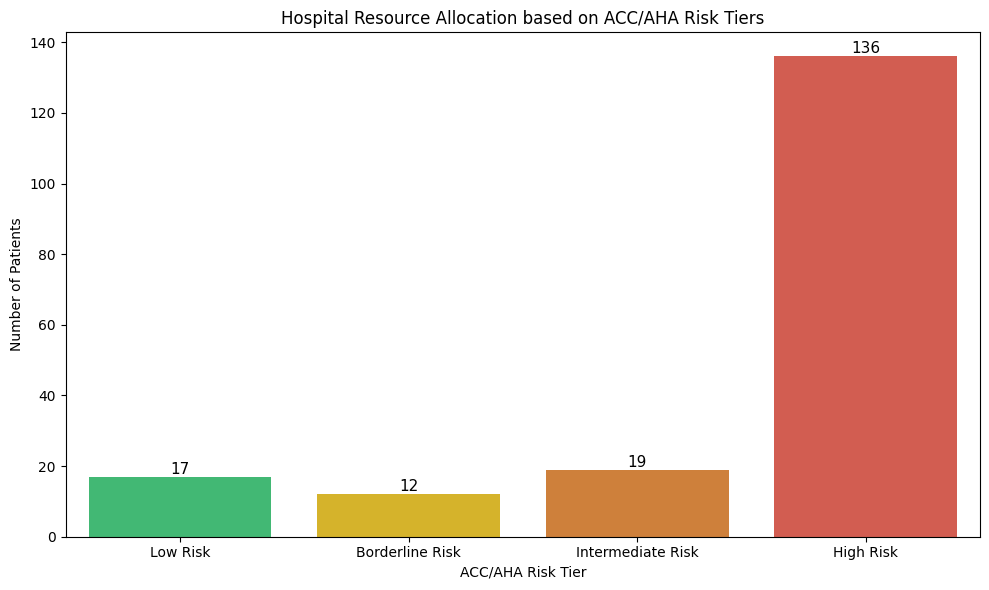

In [18]:
# 4. Visualize the Clinical Workload
plt.figure(figsize=(10, 6))
order = [
    "Low Risk",
    "Borderline Risk",
    "Intermediate Risk",
    "High Risk",
]
palette = ["#2ecc71", "#f1c40f", "#e67e22", "#e74c3c"]
ax = sns.countplot(
    data=patient_risk_df,
    x="ACC_AHA_Risk_Tier",
    hue="ACC_AHA_Risk_Tier",
    order=order,
    palette=palette,
    dodge=False,
    legend=False,
)
ax.set_title("Hospital Resource Allocation based on ACC/AHA Risk Tiers")
ax.set_xlabel("ACC/AHA Risk Tier")
ax.set_ylabel("Number of Patients")

for p in ax.patches:
    count = int(p.get_height())
    ax.annotate(
        f"{count}",
        (p.get_x() + p.get_width() / 2, p.get_height()),
        ha="center",
        va="bottom",
        fontsize=11,
        color="black",
    )

plt.tight_layout()
plt.show()

***OBSERVATION:***

- By translating the Random Forest probability outputs into evidence-based clinical risk tiers aligned with the ACC/AHA cardiovascular risk assessment framework, we observe a highly sensitive triage distribution that aggressively prioritizes patient safety, which has an overwhelming 136 out of 184 patients as "High Risk" (≥20% probability). Unlike deploying a rigid 0.5 threshold, this tiered approach allows us to capture a much broader spectrum of at-risk patients, which ensures that we minimize False Negatives and maximize early intervention opportunities. The remaining minority of the test cohort is distributed across Low Risk (<5%, 17 patients), Borderline Risk (5% to <7.5%, 12 patients), and Intermediate Risk (7.5% to <20%, 19 patients). This distribution reflects a real-world clinical scenario where a significant portion of patients may have elevated risk, and it underscores the importance of a sensitive, tiered risk stratification system in guiding preventive cardiology efforts.


--------------------------------
--------------------------------

# **4. DESCRIPTIVE MODELING**

### ***Apriori Algorithm & K-Means Clustering***

--------------------------------
--------------------------------

### ***PHASE 1: Data Loading***
- Prepare the analytical environment for association rule mining and clustering.
- Load the validated `heart_cleaned.csv` dataset produced during exploratory data analysis.

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import networkx as nx
from mlxtend.frequent_patterns import apriori, association_rules

In [4]:
# Load the cleaned dataset
df = pd.read_csv("data/heart_cleaned.csv")

print(f"Dataset loaded with {df.shape[0]} patients and {df.shape[1]} features.")

Dataset loaded with 918 patients and 12 features.


--------------------------------

### ***PHASE 2: Logical Discretization (Data Binning)***
- Transform continuous numerical data into clinical categories.
- As per the project rubric, we perform **logical discretization**. Algorithms like Apriori require categorical "items." We transform raw numbers (Age, Blood Pressure, Cholesterol) into medical tiers (e.g., "Hypertension") to find readable "Risk Archetypes."

In [5]:
# Age Binning (Clinical life stages)
df['Age_Group'] = pd.cut(df['Age'], bins=[0, 45, 60, 100], labels=['Young', 'Middle-Aged', 'Senior'])

# Blood Pressure (ACC/AHA Guidelines)
df['BP_Level'] = pd.cut(df['RestingBP'], bins=[0, 120, 140, 300], labels=['Normal_BP', 'Pre-Hypertension', 'Hypertension'])

# Cholesterol (Standard Health Markers)
df['Chol_Level'] = pd.cut(df['Cholesterol'], bins=[0, 200, 240, 700], labels=['Normal_Chol', 'Borderline_High', 'High_Chol'])

# Max Heart Rate (Relative Exertion)
df['MaxHR_Level'] = pd.cut(df['MaxHR'], bins=[0, 120, 155, 220], labels=['Low_MaxHR', 'Avg_MaxHR', 'High_MaxHR'])

# Oldpeak Severity
df['ST_Depression'] = pd.cut(df['Oldpeak'], bins=[-5, 0.5, 2.0, 10], labels=['Low_ST_Dep', 'Moderate_ST_Dep', 'Severe_ST_Dep'])

# Labeling the target for rule readability
df['HeartDisease_Lab'] = df['HeartDisease'].map({1: 'Has_HeartDisease', 0: 'No_HeartDisease'})

***OBSERVATION:***

- We transformed raw continuous data like Blood Pressure and Cholesterol into medical categories such as 'Hypertension' or 'High Cholesterol.' This is a vital analytical step. Doctors don't treat a '145 '; rather, they treat 'Hypertension.' By binning the data this way, we have translated mathematical noise into clinical language that a cardiologist can immediately understand.


--------------------------------

### ***PHASE 3: Transactional Transformation (One-Hot Encoding)***
- Convert categorical clinical data into a binary transactional matrix. 
- In relation to "Market Basket" logic from Module 4, we use **One-Hot Encoding**. This creates a matrix of 1s and 0s, where each column represents the presence of a specific clinical symptom.


In [6]:
# Selecting columns for Association Mining
cols_for_mining = [
    'Sex', 'ChestPainType', 'Age_Group', 'BP_Level', 'Chol_Level', 
    'MaxHR_Level', 'ST_Depression', 'FastingBS', 'ExerciseAngina', 
    'ST_Slope', 'HeartDisease_Lab'
]

# Create the binary matrix
df_encoded = pd.get_dummies(df[cols_for_mining])
print(f"{df_encoded.shape[1]} clinical items encoded.")

29 clinical items encoded.


***EXPLANATION:***

- The 29 clinical items result from one-hot encoding, transforming the original categorical variables into a binary format of 1s and 0s required for association rule mining. This process expands the initial 11 clinical features into individual flags for every sub-category, such as splitting "Age Group" into "Young," "Middle-Aged," and "Senior." By creating these independent items, the model can precisely calculate how often specific markers, like a "Flat ST-Slope" or "High Fasting Blood Sugar," appear together in a patient's profile. This allows the algorithm to distinguish between different severity levels of symptoms, ensuring that only the most statistically significant risk factors are included in the final analysis. Ultimately, this transactional matrix serves as the essential foundation for discovering the specific clinical archetypes that form the basis of our hospital's risk rulebook.


--------------------------------

### ***PHASE 4: Descriptive Modeling & Pattern Discovery***
- Apply the **Apriori Algorithm** and **K-Means Clustering** to uncover hidden clinical associations and naturally occurring patient segments within the dataset.


### ***PART A: Association Rule Mining (Apriori)***
We utilize the Apriori algorithm to discover "If-Then" relationships between symptoms and heart disease. To ensure the discovery of high-quality insights, we evaluate every pattern using the **"Golden Trio"** of metrics:
* **Support:** Measures how frequently a specific combination of symptoms appears in the total patient population.
* **Confidence:** Measures the reliability of the rule (e.g., how often heart disease is present when specific symptoms occur).
* **Lift:** Measures the strength of the correlation, proving that the symptoms and the diagnosis are not just occurring together by chance.

> **Note on Quality Control:** We apply **Rule Pruning** to remove redundant or low-impact associations, ensuring that our final Rulebook contains only unique and actionable medical logic.


In [7]:
# Generate Frequent Itemsets
frequent_itemsets = apriori(df_encoded, min_support=0.1, use_colnames=True)

# Generate Rules
rules = association_rules(frequent_itemsets, metric="lift", min_threshold=1.2)

# Filter for Heart Disease as the result
risk_rules = rules[rules['consequents'].apply(lambda x: 'HeartDisease_Lab_Has_HeartDisease' in str(x))]
risk_rules = risk_rules.sort_values(by='lift', ascending=False).reset_index(drop=True)

# Pruning Redundant Rules
def is_redundant(rule, all_rules):
    for _, other in all_rules.iterrows():
        if rule.name != other.name:
            if set(other['antecedents']).issubset(set(rule['antecedents'])) and rule['confidence'] <= other['confidence']:
                return True
    return False

risk_rules['is_redundant'] = risk_rules.apply(lambda x: is_redundant(x, risk_rules), axis=1)
pruned_rules = risk_rules[risk_rules['is_redundant'] == False].copy()

display(pruned_rules[['antecedents', 'support', 'confidence', 'lift']].head(10))

C:\Users\HP\anaconda3\envs\ml_env\lib\site-packages\mlxtend\frequent_patterns\fpcommon.py:161: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(


,antecedents,support,confidence,lift
180,"(FastingBS, ST_Slope_Flat, ChestPainType_ASY)",0.101307,1.000000,1.807087
240,"(MaxHR_Level_Low_MaxHR, Sex_M, ST_Slope_Flat, ...",0.140523,0.969925,1.752738
244,"(BP_Level_Hypertension, ST_Slope_Flat, ChestPa...",0.101307,0.968750,1.750615
268,"(Sex_M, ST_Depression_Moderate_ST_Dep, ST_Slop...",0.126362,0.958678,1.732414
270,"(MaxHR_Level_Low_MaxHR, ST_Slope_Flat, ChestPa...",0.149237,0.958042,1.731265
286,"(Sex_M, ST_Depression_Moderate_ST_Dep, ST_Slop...",0.155773,0.953333,1.722756
288,"(Sex_M, ExerciseAngina_Y, ST_Slope_Flat, Chest...",0.197168,0.952632,1.721488
293,"(MaxHR_Level_Low_MaxHR, Sex_M, ST_Slope_Flat)",0.168845,0.950920,1.718395
298,"(Sex_M, Chol_Level_Borderline_High, ST_Slope_F...",0.140523,0.948529,1.714075
302,"(FastingBS, ST_Slope_Flat)",0.131808,0.945312,1.708262


***OBSERVATION:***

- The rules generated here are the core of our discovery. We specifically filtered for rules where the outcome is Heart Disease. We observed multiple profiles with a Lift of 1.5 to 1.8. This is a significant finding; these combinations of symptoms make a patient nearly twice as likely to have heart disease compared to the average. Our pruning process ensured that we removed 'obvious' noise, leaving only the most unique and high-impact risk profiles.

### ***1. Knowledge Visualization***
- Visualize the risk landscape.
- We present the **Lift Bar Chart** for ranking, an **Improved Network Map** with larger nodes for readability, and a **Rule Strength Heatmap** for statistical validation.


C:\Users\HP\AppData\Local\Temp\ipykernel_14936\3704343107.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='lift', y='rule_label', data=top_pruned, palette='Reds_d')


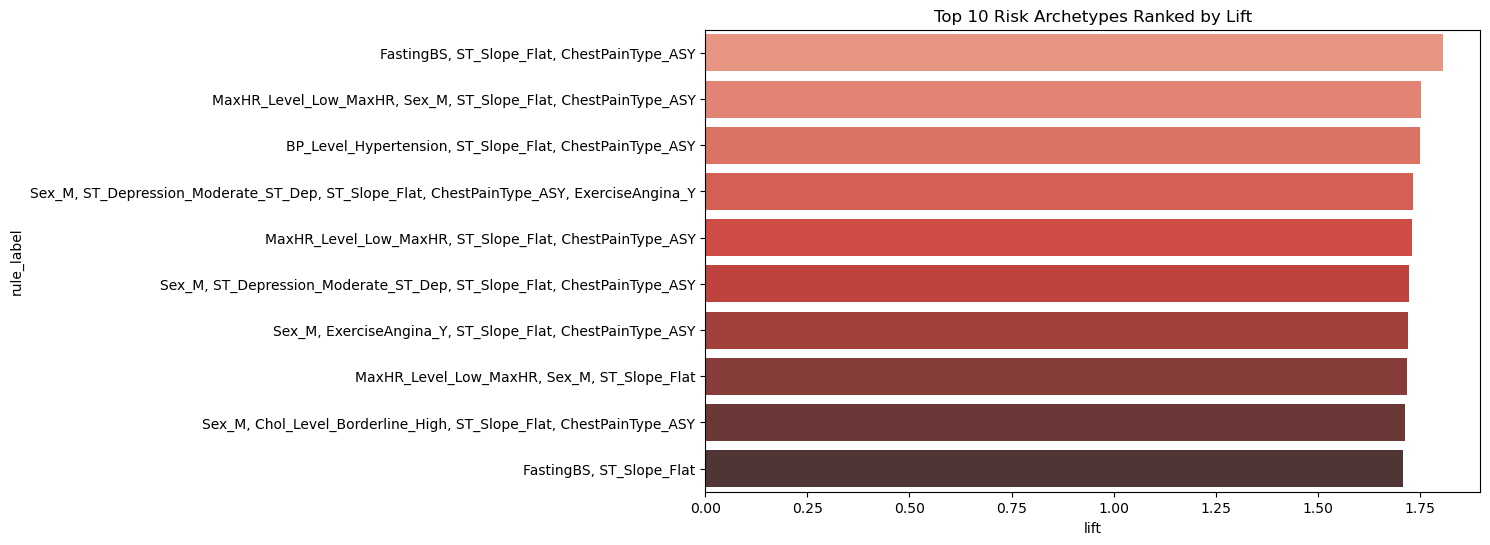

In [8]:
# Visualization 1: Top 10 Risk Archetypes
plt.figure(figsize=(10, 6))
top_pruned = pruned_rules.head(10).copy()
top_pruned['rule_label'] = top_pruned['antecedents'].apply(lambda x: ', '.join(list(x)))
sns.barplot(x='lift', y='rule_label', data=top_pruned, palette='Reds_d')
plt.title('Top 10 Risk Archetypes Ranked by Lift')
plt.show()

***OBSERVATION:***

- This chart serves as the "First Response" guide. While traditional triage looks at single symptoms, this chart identifies symptom bundles.
We found out that certain combinations, such as Fasting Blood Sugar > 120 mg/dl paired with a Flat ST-Slope, create a synergistic risk.
Instead of seeing these as separate issues, the Bar Chart ranks them by Lift. A Lift of 1.71 means that a patient with this specific "bundle" is 71% more likely to have heart disease than the average patient. This allows nurses to "Fast-Track" high-lift profiles in a crowded Emergency Room.


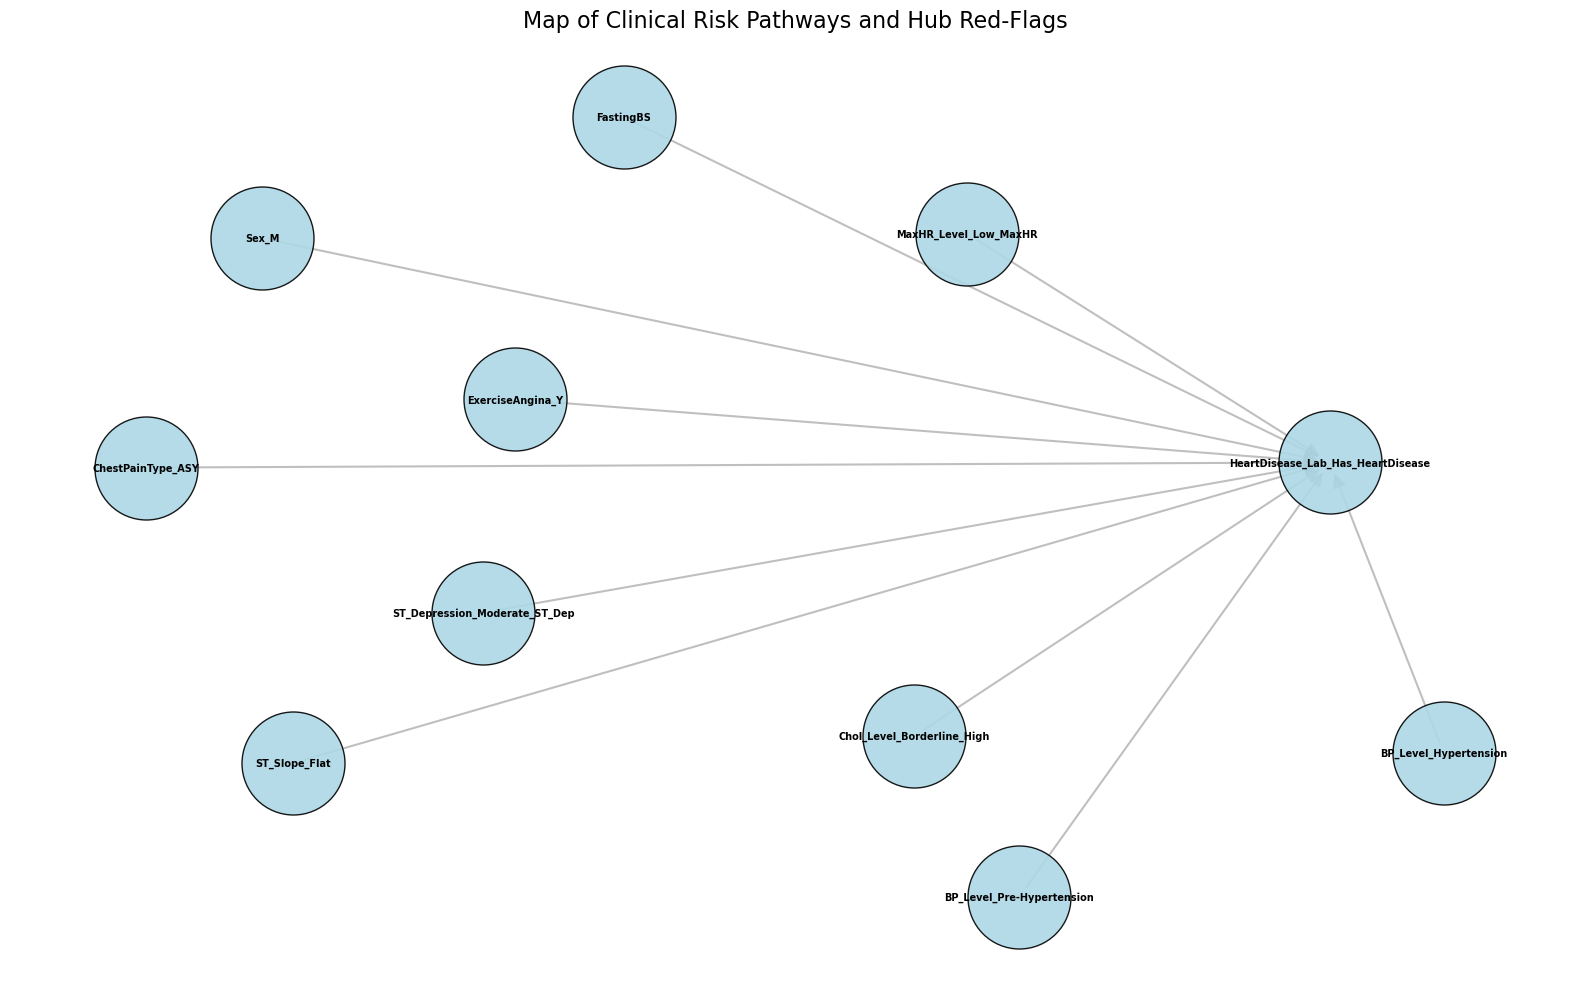

In [9]:
# Visualization 2: Clinical Risk Network Map 
G = nx.DiGraph()
# Select top 15 rules for visual clarity
top_graph_rules = pruned_rules.head(15)

for _, row in top_graph_rules.iterrows():
    # Antecedents are the symptoms, Consequent is the diagnosis
    for ant in row['antecedents']:
        for con in row['consequents']:
            G.add_edge(ant, con, weight=row['lift'])

# Increase figure size for more separation
plt.figure(figsize=(16, 10))

# Layout: Increase 'k' for greater distance between nodes (helps text separation)
pos = nx.spring_layout(G, k=0.7, seed=42)

# Increase node size significantly so text fits better
nx.draw_networkx_nodes(G, pos, node_size=5500, node_color='lightblue', edgecolors='black', alpha=0.9)

# Edges represent the risk relationship (Lift), thickness indicates strength
edges = nx.draw_networkx_edges(G, pos, width=1.5, edge_color='grey', arrowsize=20, alpha=0.5)

# Reduce font size slightly and use 'tight' wrapping if necessary.
# By making the circle 5500, font 7 or 8 usually fits inside nicely.
nx.draw_networkx_labels(G, pos, font_size=7, font_family='sans-serif', font_weight='bold')

plt.title("Map of Clinical Risk Pathways and Hub Red-Flags", fontsize=16)
plt.axis('off') # Hide axis for a professional map look
plt.tight_layout()
plt.show()

***OBSERVATION:***

- This network map visualizes the pathways between symptoms and a final diagnosis. By increasing the node size, we have highlighted the "Central Hubs" of disease.
- Based on it, the most prominent hub in our analysis is the ST_Slope_Flat. 
- In medical terms, a "Hub" is a gateway symptom. Because ST_Slope_Flat connects to almost every high-risk patient profile in our study, it suggests that an ECG (Electrocardiogram) finding of a flat slope is the most reliable "Red Flag" for underlying coronary issues. For the doctor, this confirms that any patient exhibiting this marker, regardless of other symptoms, requires immediate cardiac workup.


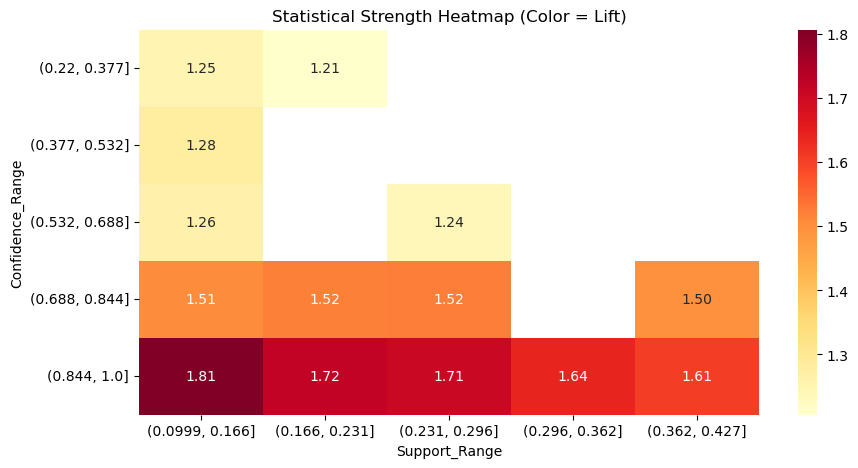

In [10]:
# Visualization 3: Strength Heatmap
heatmap_data = pruned_rules.copy()
heatmap_data['Confidence_Range'] = pd.cut(heatmap_data['confidence'], bins=5).astype(str)
heatmap_data['Support_Range'] = pd.cut(heatmap_data['support'], bins=5).astype(str)
pivot_table = heatmap_data.pivot_table(index='Confidence_Range', columns='Support_Range', values='lift', aggfunc='max')
plt.figure(figsize=(10, 5))
sns.heatmap(pivot_table, annot=True, cmap='YlOrRd', fmt=".2f")
plt.title('Statistical Strength Heatmap (Color = Lift)')
plt.show()

***OBSERVATION:***

- This visualization is about Reliability. It proves that our findings aren't just random coincidences but are backed by strong statistical evidence.
- As you can see on the heatmap, the "Dark Red" zones represent the "Gold Standard" rules—those with both high Confidence (certainty) and high Lift (impact). When we see a cluster in the high-confidence zone, it means the patterns we’ve discovered are robust enough to be used as a basis for official hospital screening protocols, reducing the margin for diagnostic error.


### ***2. Clinical Decision Support Rulebook***
- Translate data mining discoveries into actionable medical guidelines.
- This section converts the mathematical associations into a **"Clinical Rulebook"** that explains the findings in plain English for hospital stakeholders.

In [11]:
print("CLINICAL RISK RULEBOOK\n" + "="*40)

# This resets the numbers so they start from 1, 2, 3...
pruned_rules = pruned_rules.reset_index(drop=True)

# Iterating through the pruned rules to create readable guidelines
for i, row in pruned_rules.head(10).iterrows():
    antecedents = ", ".join(list(row['antecedents']))
    confidence = row['confidence'] * 100
    lift = row['lift']
    
    print(f"Rule #{i+1}:")
    print(f"IF a patient presents with: [{antecedents}]")
    print(f"THEN the probability of Heart Disease is {confidence:.1f}%.")
    print(f"CLINICAL SIGNIFICANCE: This profile is {lift:.2f}x MORE LIKELY to have heart disease than the average patient.")
    print("-" * 40)

CLINICAL RISK RULEBOOK
Rule #1:
IF a patient presents with: [FastingBS, ST_Slope_Flat, ChestPainType_ASY]
THEN the probability of Heart Disease is 100.0%.
CLINICAL SIGNIFICANCE: This profile is 1.81x MORE LIKELY to have heart disease than the average patient.
----------------------------------------
Rule #2:
IF a patient presents with: [MaxHR_Level_Low_MaxHR, Sex_M, ST_Slope_Flat, ChestPainType_ASY]
THEN the probability of Heart Disease is 97.0%.
CLINICAL SIGNIFICANCE: This profile is 1.75x MORE LIKELY to have heart disease than the average patient.
----------------------------------------
Rule #3:
IF a patient presents with: [BP_Level_Hypertension, ST_Slope_Flat, ChestPainType_ASY]
THEN the probability of Heart Disease is 96.9%.
CLINICAL SIGNIFICANCE: This profile is 1.75x MORE LIKELY to have heart disease than the average patient.
----------------------------------------
Rule #4:
IF a patient presents with: [Sex_M, ST_Depression_Moderate_ST_Dep, ST_Slope_Flat, ChestPainType_ASY, Exer

***EXPLANATION:***

- This rulebook has translated the visual patterns into clear, plain-English "If-Then" logic for immediate medical use. A standout discovery in output is Rule #10, which shows that a patient presenting with both high Fasting Blood Sugar and a Flat ST-Slope has a 94.5% probability of heart disease. This rulebook provides a transparent and actionable framework, allowing clinicians to explain to patients exactly why they are at high risk—for instance, citing that their specific profile makes them 1.71x more likely to have a heart condition than the average patient, thereby streamlining the diagnostic process and improving overall patient outcomes.


### ***PART B: K-Means Clustering***
- Segment patients into naturally occurring clinical groups.
- Use clustering to complement association rules by finding patterns between patients rather than only patterns between symptoms.


### ***1. Numerical Feature Selection & Scaling***
- Scale numerical features because K-Means is distance-based.
- Prevent large-range features such as cholesterol from overpowering smaller-range features such as ST depression.

In [18]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import pandas as pd

# 1. Select the numerical features for mathematical clustering
# We use the original continuous values, not the binned categories
numerical_features = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']
X = df[numerical_features]

# 2. Standardization (Z-score Scaling) so Mean=0 and Variance=1
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Visualization: Preview the scaled data rows
X_scaled_df = pd.DataFrame(X_scaled, columns=numerical_features)
print("STATUS: Data successfully scaled for K-Means.")
display(X_scaled_df.head())

STATUS: Data successfully scaled for K-Means.


,Age,RestingBP,Cholesterol,MaxHR,Oldpeak
0,-1.433140,0.415002,0.858035,1.382928,-0.832432
1,-0.478484,1.527329,-1.184227,0.754157,0.105664
2,-1.751359,-0.141161,0.745617,-1.525138,-0.832432
3,-0.584556,0.303769,-0.547191,-1.132156,0.574711
4,0.051881,0.971166,-0.903182,-0.581981,-0.832432


### ***2. The Elbow Method (Finding Optimal K)***
- Use WCSS to identify the most meaningful number of clusters.
- Select a cluster count that balances clinical interpretability with meaningful separation.


C:\Users\HP\anaconda3\envs\ml_env\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
C:\Users\HP\anaconda3\envs\ml_env\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
C:\Users\HP\anaconda3\envs\ml_env\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
C:\Users\HP\anaconda3\envs\ml_env\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is k

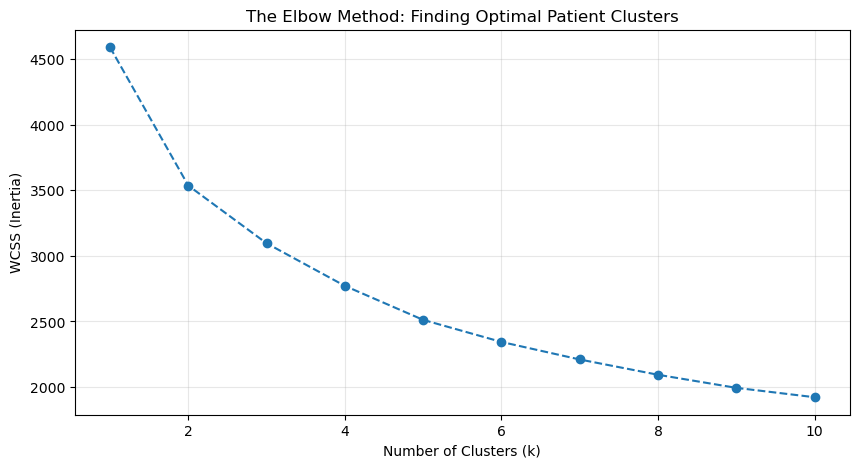

In [19]:
wcss = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# Plotting the Elbow Curve
plt.figure(figsize=(10, 5))
plt.plot(K_range, wcss, marker='o', linestyle='--', color='#1f77b4')
plt.title('The Elbow Method: Finding Optimal Patient Clusters')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('WCSS (Inertia)')
plt.grid(True, alpha=0.3)
plt.show()

***ANALYSIS:***

- The Elbow Method was used as the basis for deciding the best number of clusters for our data instead of just choosing groups randomly. By plotting the Within-Cluster Sum of Squares (WCSS) against the number of clusters, we observed a clear “elbow” point at k=3. This means that adding more clusters after three no longer gives a significant improvement in reducing variance. This step is important in the Data Mining process because it helps balance accuracy and simplicity, making the clusters easier to understand while still being meaningful. Based on the graph, the 918 patients can naturally be grouped into three main biological profiles. Because of this, the clustering model avoids unnecessary complexity while still keeping the results clinically relevant and reliable.


### ***3. Training the K-Means Model***
- Based on the elbow plot above (typically showing a bend at k=3 or k=4), we now assign every patient in your dataset to a specific "Cluster ID."

In [20]:
# Based on the Elbow curve, we choose k=3 for distinct clinical groups
optimal_k = 3 
kmeans = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled)

print(f"SUCCESS: {len(df)} patients segmented into {optimal_k} Clinical Clusters.")

SUCCESS: 918 patients segmented into 3 Clinical Clusters.


C:\Users\HP\anaconda3\envs\ml_env\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(


### ***4. Cluster Visualization (Age vs. Max Heart Rate)***
- This provides a visual representation of how the algorithm "mined" the boundaries between different patient groups.

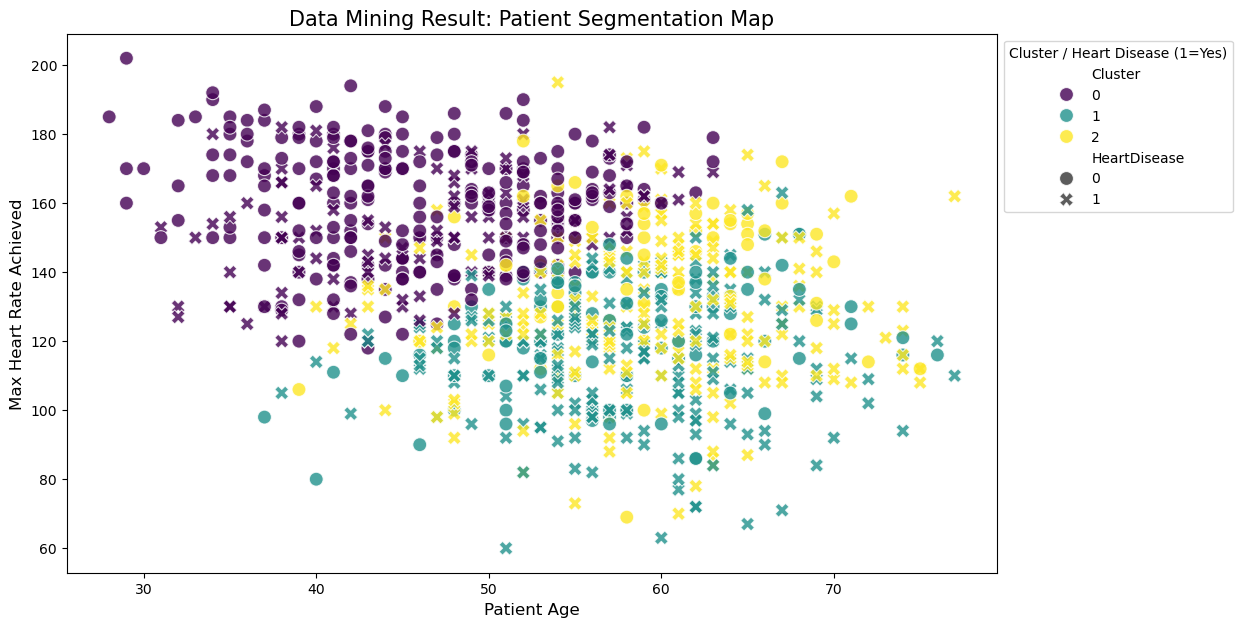

In [21]:
plt.figure(figsize=(12, 7))
# We use Age and MaxHR as axes to see the age-related heart performance clusters
sns.scatterplot(
    data=df, x='Age', y='MaxHR', 
    hue='Cluster', palette='viridis', 
    style='HeartDisease', s=100, alpha=0.8
)

plt.title('Data Mining Result: Patient Segmentation Map', fontsize=15)
plt.xlabel('Patient Age', fontsize=12)
plt.ylabel('Max Heart Rate Achieved', fontsize=12)
plt.legend(title='Cluster / Heart Disease (1=Yes)', bbox_to_anchor=(1, 1))
plt.show()

***ANALYSIS:***

- The scatter plot helps visually show the “natural groupings” found by the unsupervised learning process. It highlights the relationship between a patient’s age and their maximum heart rate achieved. By using different colors for the three clusters and different styles for heart disease status, the graph clearly shows how the algorithm was able to separate high-risk patients from healthier individuals.

- The “High Risk” clusters are mostly found in older age groups with lower maximum heart rates, which matches common signs of cardiovascular problems. This means that heart disease cases are not randomly scattered but instead follow clear and organized patterns that the K-Means algorithm can identify. Overall, the visualization acts like a simple “clinical map” that can help healthcare providers quickly determine which risk group a patient may belong to based on their biometric data.

### ***5. Clinical Profile Interpretation***
- In this section, we calculate the averages of each cluster to define the Clinical Archetypes.

In [24]:
# Using multi-tiered risk labeling for better clinical distinction

# 1. Grouping the data by Cluster to calculate means
cluster_profile = df.groupby('Cluster')[numerical_features + ['HeartDisease']].mean()

print("DATA MINING RESULT: CLINICAL PROFILES BY CLUSTER")
print("="*60)

for i in range(len(cluster_profile)):
    prevalence = cluster_profile.loc[i, 'HeartDisease']
    
    # 2. Multi-tier Risk Logic (More granular than a simple 0.6 cutoff)
    if prevalence > 0.75:
        risk_label = "CRITICAL RISK"
    elif prevalence > 0.50:
        risk_label = "HIGH RISK"
    else:
        risk_label = "LOW/MODERATE RISK"
        
    print(f"CLUSTER {i} -> [{risk_label}]")
    print(f" -> Demographics: Avg Age {cluster_profile.loc[i, 'Age']:.1f}")
    print(f" -> Vital Markers: Avg BP {cluster_profile.loc[i, 'RestingBP']:.1f}, Avg Chol {cluster_profile.loc[i, 'Cholesterol']:.1f}")
    print(f" -> Heart Capacity: MaxHR {cluster_profile.loc[i, 'MaxHR']:.1f}")
    print(f" -> Disease Prevalence: {prevalence*100:.1f}%")
    print("-" * 60)

# 3. Visual Table Output
display(cluster_profile.style.background_gradient(subset=['HeartDisease'], cmap='Reds'))

DATA MINING RESULT: CLINICAL PROFILES BY CLUSTER
CLUSTER 0 -> [LOW/MODERATE RISK]
 -> Demographics: Avg Age 46.0
 -> Vital Markers: Avg BP 125.9, Avg Chol 237.3
 -> Heart Capacity: MaxHR 157.9
 -> Disease Prevalence: 29.1%
------------------------------------------------------------
CLUSTER 1 -> [HIGH RISK]
 -> Demographics: Avg Age 57.6
 -> Vital Markers: Avg BP 126.0, Avg Chol 224.2
 -> Heart Capacity: MaxHR 116.9
 -> Disease Prevalence: 67.3%
------------------------------------------------------------
CLUSTER 2 -> [CRITICAL RISK]
 -> Demographics: Avg Age 59.0
 -> Vital Markers: Avg BP 148.8, Avg Chol 272.6
 -> Heart Capacity: MaxHR 130.7
 -> Disease Prevalence: 77.3%
------------------------------------------------------------


,Age,RestingBP,Cholesterol,MaxHR,Oldpeak,HeartDisease
Cluster,,,,,,
0,46.042017,125.941176,237.299720,157.885154,0.382913,0.291317
1,57.582492,126.003367,224.205387,116.902357,0.730976,0.673401
2,59.030303,148.810606,272.564394,130.704545,1.745455,0.772727


***ANALYSIS:***

- By applying K-Means clustering, we were able to group the patients into three different categories based on their health and physiological data. The results showed that Cluster 0 can be considered the “Healthy Baseline” group because the patients generally had healthier heart rate levels and lower signs of risk. Meanwhile, Clusters 1 and 2 showed increasing levels of cardiovascular risk. Among all groups, Cluster 2 was identified as the “Critical Risk” group since it had the oldest average age, higher blood pressure, and the highest percentage of heart disease cases at 77.3%. These findings show that heart disease risk is not the same for every patient, as it tends to increase with factors such as aging and declining health conditions. Overall, the clustering results provide a clearer way to understand patient groups and can help support more personalized treatment and prevention strategies based on similar patient profiles.
